# Olist E-commerce: Final Integrated Analysis

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): about 99k orders placed on the Olist marketplace between September 2016 and October 2018, with customers, sellers, products, payments, reviews and geolocation.

**Objective:** combine the analyses of all team members into one reproducible notebook that runs from the raw CSV files to the final business insights. Every number in the management report (`reports/management_report.pdf`) is produced here and exported to `outputs/key_metrics.json`.

**How to run:** put the raw Kaggle CSV files in `Data/Raw/` (see `README.md`), install `requirements.txt`, and run all cells from top to bottom (*Kernel → Restart & Run All*). The notebook rebuilds the cleaned tables in `Data/Processed/` and overwrites the charts in `outputs/charts/` and the tables in `outputs/tables/`.

| # | Section | Based on team notebook |
|---|---|---|
| 1 | Data Loading and Profiling | `1_understanding_data` |
| 2 | Data Cleaning and Feature Engineering | `2_data_cleaning` (logic moved to `src/cleaning.py`) |
| 3 | Order Status and Time Analysis | `3_order_status_time_trends` |
| 4 | Customer and Geographic Analysis | `4_Customer_Geographic_Analysis` |
| 5 | Product and Payment Analysis | `5_Product_Category_&_Payment_Analysis` |
| 6 | Delivery Performance Analysis | `6_Delivery_Performance_Analysis` |
| 7 | Review and Customer Satisfaction Analysis | `7_review_and_customer_satisfication` |
| 8 | Seller Performance Analysis | `8_Seller_Performance_Analysis` |
| 9 | Advanced Multi-table Analysis | new in this notebook |
| 10 | Final Business Insights and Quality Checks | new in this notebook |

All amounts are in Brazilian reais (R$).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# find the project root (the folder that contains src/), so the notebook runs from any working directory
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
from src.config import VALID_START, VALID_END, REGION_OF_STATE
from src.data_loading import load_raw, load_population, profile_table, missing_report
from src.cleaning import run_cleaning, check_merge, haversine_km
from src.metrics import (METRIC_DEFINITIONS, build_order_table, latest_review_per_order, revenue_summary,
                         delivery_summary, delivered)
from src.viz import set_style, save_fig, thousands, BLUE, LIGHT_BLUE, ORANGE, RED, GREEN, GRAY

config.ensure_output_dirs()
set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

KM = {}   # key metrics collected along the notebook, exported at the end for the management report
print("Project root:", ROOT.name, "| pandas", pd.__version__)

Project root: Olist-data-analysis | pandas 3.1.1


---
## 1. Data Loading and Profiling

**Goal:** load the nine raw tables, confirm their grain (what one row represents) and keys, and record the data quality issues that the cleaning step must handle.

The `orders` table is the centre of the data model. It links to `customers` through `customer_id`, and to `order_items`, `payments` and `reviews` through `order_id`. `order_items` links each item to `products` and `sellers`, and customers and sellers can be placed on the map through the ZIP prefix in `geolocation`.

In [2]:
raw = load_raw()
population = load_population()

keys = {
    "orders": ["order_id"], "order_items": ["order_id", "order_item_id"], "customers": ["customer_id"],
    "payments": ["order_id", "payment_sequential"], "reviews": ["review_id", "order_id"],
    "sellers": ["seller_id"], "products": ["product_id"], "category_translation": ["product_category_name"],
    "geolocation": None,
}
grain = {
    "orders": "one order", "order_items": "one item of an order", "customers": "one customer record per order",
    "payments": "one payment record", "reviews": "one review of an order", "sellers": "one seller",
    "products": "one product", "category_translation": "one category", "geolocation": "one coordinate point",
}
profile = pd.DataFrame([profile_table(n, raw[n], keys[n]) for n in raw])
profile.insert(1, "grain (one row =)", profile["table"].map(grain))
profile

,table,grain (one row =),rows,columns,exact_duplicates,key,duplicate_keys,columns_with_missing,missing_cells_%
0,orders,one order,99441,8,0,order_id,0.00,3,0.62
1,order_items,one item of an order,112650,7,0,"order_id, order_item_id",0.00,0,0.00
2,customers,one customer record per order,99441,5,0,customer_id,0.00,0,0.00
3,payments,one payment record,103886,5,0,"order_id, payment_sequential",0.00,0,0.00
4,reviews,one review of an order,99224,7,0,"review_id, order_id",0.00,2,21.01
5,sellers,one seller,3095,4,0,seller_id,0.00,0,0.00
6,products,one product,32951,9,0,product_id,0.00,8,0.83
7,category_translation,one category,71,2,0,product_category_name,0.00,0,0.00
8,geolocation,one coordinate point,1000163,5,261831,(none),NaN,0,0.00


**Interpretation.** All primary keys are unique (`duplicate_keys = 0`), and only `geolocation` has exact duplicate rows (261,831). Three points matter for every later section:

- `orders`, `customers` and `payments` have different row counts (99,441 / 99,441 / 103,886): **one order can have several payment records**, so payment rows must never be counted as orders.
- `customers` has one `customer_id` per order. A real person is identified by `customer_unique_id`, so unique customers must be counted with it.
- `geolocation` has many points per ZIP prefix and must be reduced to one row per prefix before any join.

In [3]:
print("Missing values in orders:")
display(missing_report(raw["orders"]))
print("Missing values in products and reviews:")
display(pd.concat({"products": missing_report(raw["products"]), "reviews": missing_report(raw["reviews"])}))

print(f"customer_id values: {raw['customers']['customer_id'].nunique():,} | "
      f"customer_unique_id values: {raw['customers']['customer_unique_id'].nunique():,}")
print(f"payment records: {len(raw['payments']):,} | orders with a payment: {raw['payments']['order_id'].nunique():,}")
print("Purchase dates:", raw["orders"]["order_purchase_timestamp"].min(), "->", raw["orders"]["order_purchase_timestamp"].max())

Missing values in orders:


,missing_count,missing_%
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16


Missing values in products and reviews:


missing_count  missing_%
products product_category_name                 610       1.85
         product_name_lenght                   610       1.85
         product_description_lenght            610       1.85
         product_photos_qty                    610       1.85
         product_weight_g                        2       0.01
         product_length_cm                       2       0.01
         product_height_cm                       2       0.01
         product_width_cm                        2       0.01
reviews  review_comment_title                87656      88.34
         review_comment_message              58247      58.70

customer_id values: 99,441 | customer_unique_id values: 96,096
payment records: 103,886 | orders with a payment: 99,440
Purchase dates: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


**Interpretation.** Missing delivery timestamps belong mostly to orders that never reached that stage (shipped, canceled, unavailable), so they are expected and are **not** imputed. 610 products (1.85%) have no category and no descriptive attributes, and review comments are optional (59% of reviews have no message). The data covers purchases from 4 September 2016 to 17 October 2018.

---
## 2. Data Cleaning and Feature Engineering

**Goal:** turn the raw tables into analysis-ready tables, add the features used later, and make sure joins cannot multiply rows or inflate totals.

The full investigation is documented in the team notebook `2_data_cleaning.ipynb`. Its decisions were moved into reusable functions in `src/cleaning.py`, which reproduce the same nine Parquet files exactly. The main rules:

| Table | Decision |
|---|---|
| orders | timestamps converted to datetime; 2 malformed dates fixed; 84 impossible timestamps set to missing; 4 `flag_*` columns for chronological anomalies; delivery features added |
| customers / sellers | ZIP prefix kept as a 5-character string (leading zeros); seller city names standardized |
| products | categories translated to English (2 translated manually); 610 products without a category labelled `unknown` |
| geolocation | exact duplicates and 33 points outside Brazil removed; `geolocation_prefix` = one row per ZIP prefix (median coordinates) |
| payments | 2 invalid zero installment counts set to missing |
| reviews | dates converted; shared `review_id` values kept (always the same customer) |

No order, customer, item, product, seller, payment or review row was deleted.

In [4]:
tables, cleaning_log = run_cleaning(raw, save=True)

rows = pd.DataFrame({
    "rows_raw": [len(raw[k]) for k in ["orders", "customers", "products", "order_items", "geolocation",
                                       "sellers", "payments", "reviews"]],
}, index=["orders", "customers", "products", "order_items", "geolocation", "sellers", "payments", "reviews"])
rows["rows_clean"] = [len(tables[f"{k}_clean"]) for k in rows.index]
rows["columns_clean"] = [tables[f"{k}_clean"].shape[1] for k in rows.index]
display(rows)
print("geolocation_prefix rows (one per ZIP prefix):", len(tables["geolocation_prefix"]))
print("Order timestamp anomalies:", cleaning_log["orders"])

,rows_raw,rows_clean,columns_clean
orders,99441,99441,21
customers,99441,99441,5
products,32951,32951,9
order_items,112650,112650,7
geolocation,1000163,720461,5
sellers,3095,3095,4
payments,103886,103886,5
reviews,99224,99224,7


geolocation_prefix rows (one per ZIP prefix): 19010
Order timestamp anomalies: {'timestamps_set_to_NaT': 84, 'flag_carrier_before_purchase': 166, 'flag_customer_before_carrier': 23, 'flag_approval_after_customer': 61, 'flag_approval_after_carrier': 1298}


**Feature engineering (orders).** The cleaning step adds the features used in sections 3 to 9:

- `order_year`, `order_month`, `order_day`, `order_weekday` from the purchase timestamp;
- `delivery_duration_days` = customer delivery date − purchase timestamp;
- `delivery_delay_days` = delivery **date** − estimated delivery date, in calendar days (the estimate has no time part, so an order delivered on the promised day counts as on time), and `is_late = delivery_delay_days > 0`;
- `approval_hours` and `carrier_to_customer_days` for the intermediate steps.

In [5]:
o = tables["orders_clean"]
d_ = o[(o["order_status"] == "delivered") & o["order_delivered_customer_date"].notna()]
old_late = (d_["order_delivered_customer_date"] > d_["order_estimated_delivery_date"]).sum()
print(f"Delivered orders with a delivery date: {len(d_):,}")
print(f"Late with a timestamp comparison: {old_late:,} | late with the calendar-day rule: {int(d_['is_late'].sum()):,} "
      f"(difference = orders delivered on the promised day: {old_late - int(d_['is_late'].sum()):,})")
display(o[["delivery_duration_days", "delivery_delay_days", "approval_hours", "carrier_to_customer_days"]]
        .describe().T[["count", "mean", "50%", "min", "max"]])

Delivered orders with a delivery date: 96,470
Late with a timestamp comparison: 7,826 | late with the calendar-day rule: 6,534 (difference = orders delivered on the promised day: 1,292)


,count,mean,50%,min,max
delivery_duration_days,"96,476.00",12.56,10.22,0.53,209.63
delivery_delay_days,"96,476.00",-11.88,-12.00,-147.00,188.00
approval_hours,"99,220.00",10.34,0.34,0.00,"4,509.18"
carrier_to_customer_days,"96,452.00",9.33,7.10,0.00,205.19


### 2.1 Join validation

Before any multi-table analysis, every join is checked: many-to-one joins must keep the row count and the price total, and one-to-many tables (payments, reviews, geolocation) must be aggregated first.

In [6]:
T = tables
pay_agg = T["payments_clean"].groupby("order_id", as_index=False)["payment_value"].sum()
rev_agg = latest_review_per_order(T["reviews_clean"])[["order_id", "review_score"]]
geo_c = T["geolocation_prefix"].rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix"})

joins = pd.DataFrame([
    check_merge(T["orders_clean"], T["customers_clean"], "customer_id", "orders -> customers"),
    check_merge(T["order_items_clean"], T["orders_clean"][["order_id", "order_status"]], "order_id", "order_items -> orders", "price"),
    check_merge(T["order_items_clean"], T["products_clean"], "product_id", "order_items -> products", "price"),
    check_merge(T["order_items_clean"], T["sellers_clean"], "seller_id", "order_items -> sellers", "price"),
    check_merge(T["orders_clean"], T["payments_clean"], "order_id", "orders -> payments (raw, do not use)"),
    check_merge(T["orders_clean"], T["reviews_clean"], "order_id", "orders -> reviews (raw, do not use)"),
    check_merge(T["order_items_clean"], T["payments_clean"], "order_id", "order_items -> payments (raw, do not use)", "price"),
    check_merge(T["orders_clean"], pay_agg, "order_id", "orders -> payments (aggregated per order)"),
    check_merge(T["orders_clean"], rev_agg, "order_id", "orders -> reviews (latest review per order)"),
    check_merge(T["customers_clean"], geo_c, "customer_zip_code_prefix", "customers -> geolocation_prefix"),
])
joins

,join,rows_before,rows_after,row_change,unmatched_left_rows,price_change
0,orders -> customers,99441,99441,0,0,NaN
1,order_items -> orders,112650,112650,0,0,0.00
2,order_items -> products,112650,112650,0,0,0.00
3,order_items -> sellers,112650,112650,0,0,0.00
4,"orders -> payments (raw, do not use)",99441,103887,4446,1,NaN
5,"orders -> reviews (raw, do not use)",99441,99992,551,768,NaN
6,"order_items -> payments (raw, do not use)",112650,117604,4954,3,"617,606.61"
7,orders -> payments (aggregated per order),99441,99441,0,1,NaN
8,orders -> reviews (latest review per order),99441,99441,0,768,NaN
9,customers -> geolocation_prefix,99441,99441,0,279,NaN


**Interpretation.** The four many-to-one joins keep both the row count and the total `price` (R$13,591,643.70). Raw joins to `payments` and `reviews` add rows (+4,446 and +551), and joining `order_items` directly to `payments` would **inflate product sales by R$617,607 (about 4.5%)**. After aggregating payments per order and keeping the latest review per order, both joins keep exactly 99,441 rows. Unmatched rows are expected: 1 order without a payment, 768 orders without a review, 279 customer ZIP prefixes without coordinates.

### 2.2 Shared metric definitions and the order table

To keep the sections consistent, the metrics below are defined once in `src/metrics.py` and used everywhere. The **order table** joins six cleaned tables (orders, customers, items, products via items, payments, reviews) at one row per order.

In [7]:
display(METRIC_DEFINITIONS)

orders_t = build_order_table(tables)
print(f"order table: {len(orders_t):,} rows (orders: {len(tables['orders_clean']):,}) | "
      f"duplicate order_id: {orders_t['order_id'].duplicated().sum()}")

rev = revenue_summary(orders_t)
dlv = delivery_summary(orders_t)
print(f"Revenue (price + freight): R${rev['revenue']:,.2f} | product sales: R${rev['product_sales']:,.2f} | "
      f"freight: R${rev['freight']:,.2f}")
print(f"Orders with items: {rev['orders_with_items']:,} | AOV = revenue / orders = R${rev['aov']:,.2f} "
      f"(mean of per-order revenue: R${rev['aov_check_mean']:,.2f})")
print(f"Amount paid (payments, includes installment interest): R${orders_t['amount_paid'].sum():,.2f}")

KM.update({
    "orders": len(orders_t), "unique_customers": int(orders_t["customer_unique_id"].nunique()),
    "customer_records": int(orders_t["customer_id"].nunique()), "sellers": len(tables["sellers_clean"]),
    "products": len(tables["products_clean"]), "items": len(tables["order_items_clean"]),
    "revenue": rev["revenue"], "product_sales": rev["product_sales"], "freight": rev["freight"],
    "aov": rev["aov"], "orders_with_items": rev["orders_with_items"],
    "amount_paid": float(orders_t["amount_paid"].sum()), "payment_records": len(tables["payments_clean"]),
})

,metric,definition,source table
0,Orders,nunique(order_id) in orders,orders
1,Unique customers,nunique(customer_unique_id),customers
2,Product sales,SUM(price),order_items
3,Revenue (GMV),"SUM(price + freight_value), aggregated per order",order_items
4,Average order value (AOV),Revenue / orders with items,order_items
5,Amount paid,"SUM(payment_value), aggregated per order (incl...",payments
6,Review score,latest review per order (1-5),reviews
7,Negative review,review score 1 or 2,reviews
8,Delivered order,status 'delivered' and customer delivery date ...,orders
9,Delivery time,delivered_customer_date - purchase_timestamp (...,orders


order table: 99,441 rows (orders: 99,441) | duplicate order_id: 0
Revenue (price + freight): R$15,843,553.24 | product sales: R$13,591,643.70 | freight: R$2,251,909.54
Orders with items: 98,666 | AOV = revenue / orders = R$160.58 (mean of per-order revenue: R$160.58)
Amount paid (payments, includes installment interest): R$16,008,872.12


**Interpretation.** Olist generated **R$15.84M of revenue** (R$13.59M product sales + R$2.25M freight) from 98,666 orders with items, an **average order value of R$160.58**. The two AOV calculations agree, which confirms the definition is consistent. The amount paid through payments (R$16.01M) is higher because it includes installment interest; it is reported separately and never mixed with revenue.

---
## 3. Order Status and Time Analysis

**Goal:** measure how many orders are fulfilled, how order volume and revenue developed over time, and whether there are seasonal or weekly patterns.

**Time window:** trends use **January 2017 to August 2018**. September to December 2016 has only 329 orders (with no orders at all in November 2016), and September to October 2018 has 20 leftover orders, 19 of them canceled. Those months are artefacts of data collection.

,orders,share_%,group
order_status,,,
delivered,96478,97.02,delivered
shipped,1107,1.11,in progress
canceled,625,0.63,failed
unavailable,609,0.61,failed
invoiced,314,0.32,in progress
processing,301,0.30,in progress
created,5,0.01,in progress
approved,2,0.00,in progress


,orders,share_%
group,,
delivered,96478,97.02
in progress,1729,1.74
failed,1234,1.24


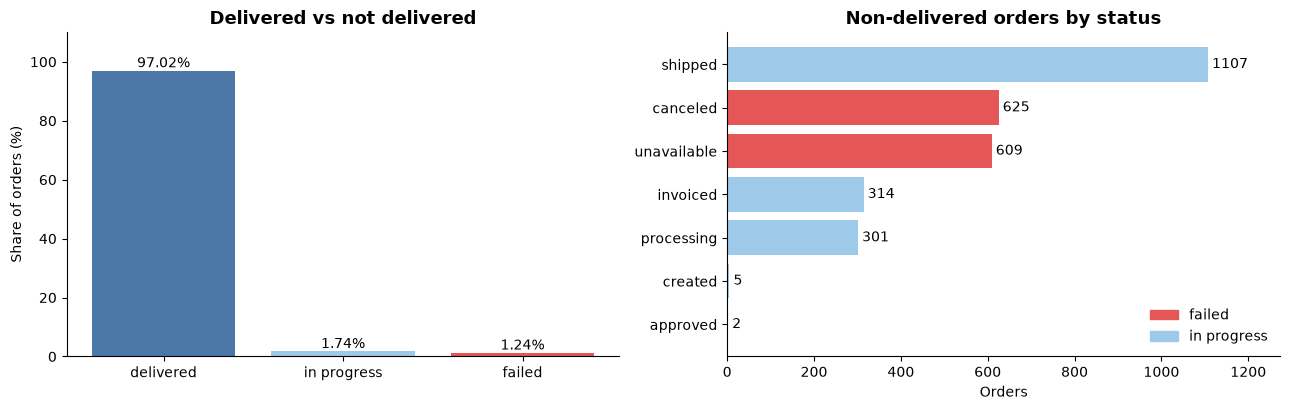

In [8]:
status = orders_t["order_status"].value_counts().to_frame("orders")
status["share_%"] = status["orders"] / status["orders"].sum() * 100
group_of = {"delivered": "delivered", "canceled": "failed", "unavailable": "failed"}
status["group"] = [group_of.get(s, "in progress") for s in status.index]
groups = status.groupby("group")[["orders", "share_%"]].sum().sort_values("orders", ascending=False)
display(status.round(2)); display(groups.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
b = ax1.bar(groups.index, groups["share_%"], color=[BLUE, LIGHT_BLUE, RED])
ax1.bar_label(b, fmt="%.2f%%"); ax1.set_ylim(0, 110); ax1.set_ylabel("Share of orders (%)")
ax1.set_title("Delivered vs not delivered")
nd = status[status.index != "delivered"]
b = ax2.barh(nd.index, nd["orders"], color=nd["group"].map({"failed": RED, "in progress": LIGHT_BLUE}))
ax2.bar_label(b, padding=3); ax2.invert_yaxis(); ax2.set_xlim(0, nd["orders"].max() * 1.15)
ax2.set_title("Non-delivered orders by status"); ax2.set_xlabel("Orders")
ax2.legend(handles=[Patch(color=RED, label="failed"), Patch(color=LIGHT_BLUE, label="in progress")], loc="lower right")
plt.tight_layout(); save_fig(fig, "03_order_status"); plt.show()

KM["delivered_share_%"] = float(status.loc["delivered", "share_%"])
KM["failed_share_%"] = float(groups.loc["failed", "share_%"]); KM["failed_orders"] = int(groups.loc["failed", "orders"])

**Interpretation.** **97.02%** of orders were delivered. The real failure rate is **1.24% (1,234 orders)**: 625 canceled plus 609 *unavailable* (the product could not be supplied). About half of the failures are therefore a stock-availability problem rather than a customer decision. The remaining 1.74% are orders still in progress when the data was extracted.

,orders,revenue,orders_with_items,aov,orders_per_day,mom_orders_%
2017-01-01,800,"137,188.50",789,173.90,25.80,NaN
2017-02-01,1780,"286,280.60",1733,165.20,63.60,122.50
2017-03-01,2682,"432,048.60",2641,163.60,86.50,50.70
2017-04-01,2404,"412,422.20",2391,172.50,80.10,-10.40
2017-05-01,3700,"586,191.00",3660,160.20,119.40,53.90
2017-06-01,3245,"502,963.00",3217,156.30,108.20,-12.30
2017-07-01,4026,"584,971.60",3969,147.40,129.90,24.10
2017-08-01,4331,"668,204.60",4293,155.60,139.70,7.60
2017-09-01,4285,"720,398.90",4243,169.80,142.80,-1.10
2017-10-01,4631,"769,312.40",4568,168.40,149.40,8.10


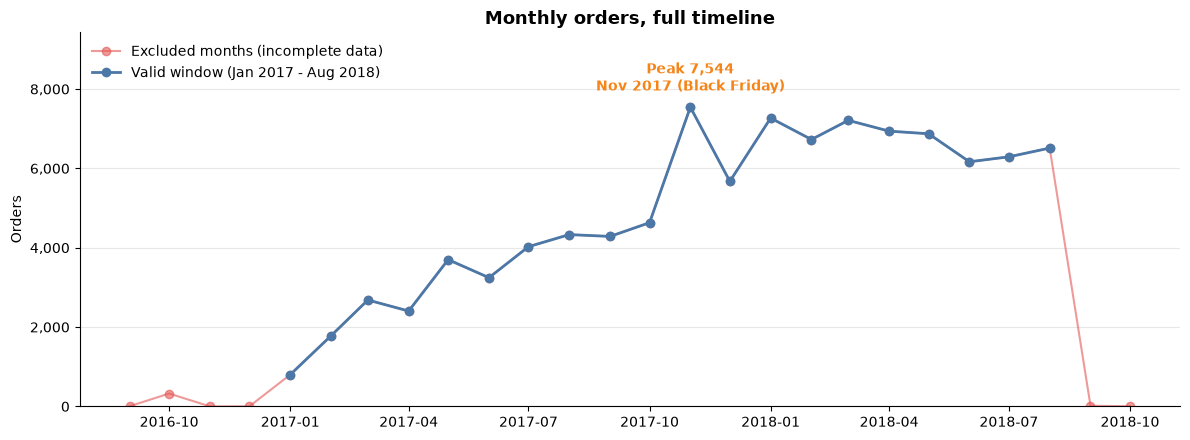

In [9]:
monthly = (orders_t.groupby("purchase_month")
           .agg(orders=("order_id", "size"), revenue=("revenue", "sum"), orders_with_items=("n_items", "count")))
monthly = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS"), fill_value=0)
monthly["aov"] = monthly["revenue"] / monthly["orders_with_items"]
valid = monthly.loc[VALID_START:VALID_END].copy()
valid["orders_per_day"] = valid["orders"] / valid.index.days_in_month
valid["mom_orders_%"] = valid["orders"].pct_change() * 100
display(valid.round(1))
valid.to_csv(config.TABLES_DIR / "monthly_orders_revenue.csv")

peak = valid["orders"].idxmax()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly["orders"], marker="o", color=RED, alpha=0.6, label="Excluded months (incomplete data)")
ax.plot(valid.index, valid["orders"], marker="o", color=BLUE, linewidth=2, label="Valid window (Jan 2017 - Aug 2018)")
ax.annotate(f"Peak {valid.loc[peak, 'orders']:,.0f}\n{peak:%b %Y} (Black Friday)", (peak, valid.loc[peak, "orders"]),
            xytext=(0, 12), textcoords="offset points", ha="center", color=ORANGE, fontweight="bold")
ax.set_ylim(0, valid["orders"].max() * 1.25); ax.set_ylabel("Orders"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Monthly orders, full timeline"); ax.legend(loc="upper left"); thousands(ax)
plt.tight_layout(); save_fig(fig, "03_monthly_orders"); plt.show()

**Interpretation.** Orders grew about **5.8x** from January (800) to October 2017 (4,631) and peaked in **November 2017 (7,544)**. After that, volume moved to a higher level and **stayed flat**: every month of 2018 is between 6,167 and 7,269 orders. The year-over-year and per-day view below shows how strong the slowdown is.

In [10]:
yoy = pd.DataFrame({"2017": valid.loc["2017-01":"2017-08", "orders"].values,
                    "2018": valid.loc["2018-01":"2018-08", "orders"].values},
                   index=pd.date_range("2018-01-01", periods=8, freq="MS").strftime("%b"))
yoy["yoy_%"] = (yoy["2018"] / yoy["2017"] - 1) * 100
display(yoy.round(1))
yoy_total = yoy["2018"].sum() / yoy["2017"].sum() - 1
per_day_feb, per_day_aug = valid.loc["2018-02-01", "orders_per_day"], valid.loc["2018-08-01", "orders_per_day"]
print(f"Jan-Aug orders: 2017 = {yoy['2017'].sum():,}, 2018 = {yoy['2018'].sum():,} ({yoy_total:+.0%})")
print(f"Orders per day: Feb 2018 = {per_day_feb:.1f}, Aug 2018 = {per_day_aug:.1f} ({per_day_aug / per_day_feb - 1:+.1%})")

rev17 = valid.loc["2017-01":"2017-08", "revenue"].sum(); rev18 = valid.loc["2018-01":"2018-08", "revenue"].sum()
print(f"Jan-Aug revenue: 2017 = R${rev17:,.0f}, 2018 = R${rev18:,.0f} ({rev18 / rev17 - 1:+.0%})")
print(f"Average monthly revenue in 2018 (Jan-Aug): R${valid.loc['2018', 'revenue'].mean():,.0f}")

KM.update({"orders_2017_jan_aug": int(yoy["2017"].sum()), "orders_2018_jan_aug": int(yoy["2018"].sum()),
           "orders_yoy_%": float(yoy_total * 100), "revenue_yoy_%": float((rev18 / rev17 - 1) * 100),
           "per_day_feb18": float(per_day_feb), "per_day_aug18": float(per_day_aug),
           "per_day_change_%": float((per_day_aug / per_day_feb - 1) * 100),
           "peak_month_orders": int(valid["orders"].max()), "first_month_orders": int(valid["orders"].iloc[0]),
           "oct17_orders": int(valid.loc["2017-10-01", "orders"]),
           "min_2018_orders": int(valid.loc["2018", "orders"].min()), "max_2018_orders": int(valid.loc["2018", "orders"].max()),
           "monthly_revenue_2018": float(valid.loc["2018", "revenue"].mean())})

,2017,2018,yoy_%
Jan,800,7269,808.60
Feb,1780,6728,278.00
Mar,2682,7211,168.90
Apr,2404,6939,188.60
May,3700,6873,85.80
Jun,3245,6167,90.00
Jul,4026,6292,56.30
Aug,4331,6512,50.40


Jan-Aug orders: 2017 = 22,968, 2018 = 53,991 (+135%)
Orders per day: Feb 2018 = 240.3, Aug 2018 = 210.1 (-12.6%)
Jan-Aug revenue: 2017 = R$3,610,270, 2018 = R$8,643,531 (+139%)
Average monthly revenue in 2018 (Jan-Aug): R$1,080,441


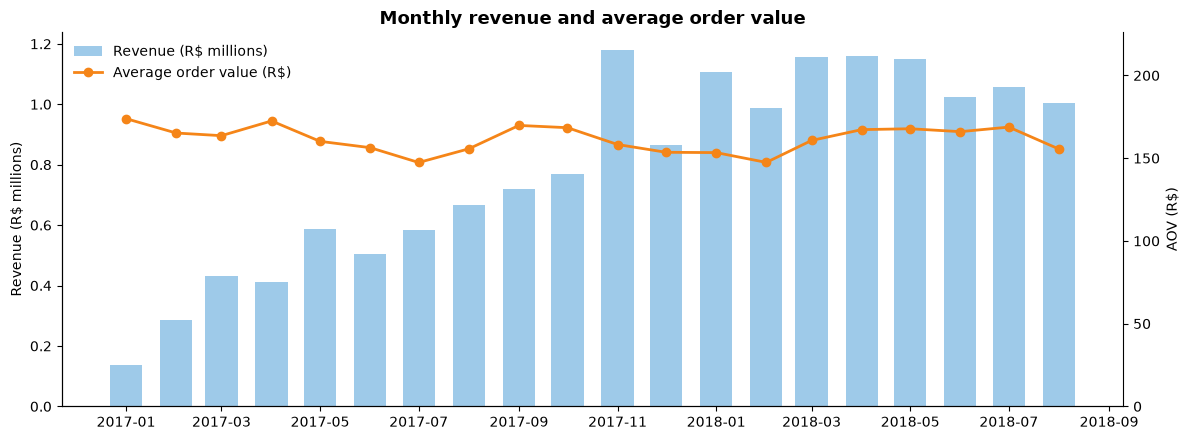

AOV range in the valid window: R$147.39 - R$173.88


In [11]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(valid.index, valid["revenue"] / 1e6, width=20, color=LIGHT_BLUE, label="Revenue (R$ millions)")
ax1.set_ylabel("Revenue (R$ millions)")
ax2 = ax1.twinx()
ax2.plot(valid.index, valid["aov"], color=ORANGE, marker="o", linewidth=2, label="Average order value (R$)")
ax2.set_ylim(0, valid["aov"].max() * 1.3); ax2.set_ylabel("AOV (R$)"); ax2.spines["right"].set_visible(True)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Monthly revenue and average order value")
plt.tight_layout(); save_fig(fig, "03_monthly_revenue_aov"); plt.show()
print(f"AOV range in the valid window: R${valid['aov'].min():,.2f} - R${valid['aov'].max():,.2f}")

**Interpretation.** Revenue follows the order count almost exactly, because the **average order value is stable** (about R$147 to R$174 per month, with no trend). The growth of 2017 therefore came from **more orders, not larger baskets**. Year over year (January to August), orders rose **+135%** and revenue **+139%**, but this only reflects the 2017 ramp-up: inside 2018, orders per day fell **12.6%** from February (240) to August (210). The data shows growth followed by a plateau, not sustained growth.

Black Friday (24 Nov 2017): 1,176 orders = 7.5x a typical day (158)


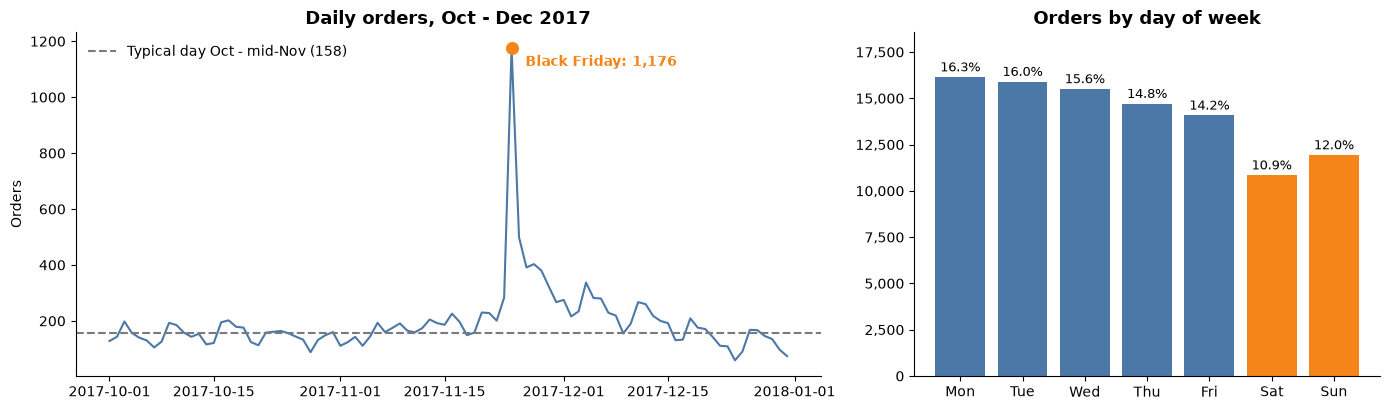

Average weekday: 15,263 orders | average weekend day: 11,388 | weekdays get 34% more


In [12]:
daily = (orders_t.set_index("order_purchase_timestamp").sort_index().loc["2017-10-01":"2017-12-31"]
         .resample("D")["order_id"].count())
typical = daily.loc["2017-10-01":"2017-11-17"].median()
bf = daily.loc["2017-11-24"]
print(f"Black Friday (24 Nov 2017): {bf:,} orders = {bf / typical:.1f}x a typical day ({typical:.0f})")

wd = orders_t[orders_t["order_purchase_timestamp"].between(VALID_START, VALID_END)]
weekday = wd["order_purchase_timestamp"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
weekday_share = weekday / weekday.sum() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(daily.index, daily.values, color=BLUE)
ax1.axhline(typical, color=GRAY, linestyle="--", label=f"Typical day Oct - mid-Nov ({typical:.0f})")
ax1.scatter(pd.Timestamp("2017-11-24"), bf, color=ORANGE, s=70, zorder=5)
ax1.annotate(f"Black Friday: {bf:,}", (pd.Timestamp("2017-11-24"), bf), xytext=(10, -5), textcoords="offset points",
             color=ORANGE, fontweight="bold", va="top")
ax1.set_title("Daily orders, Oct - Dec 2017"); ax1.legend(loc="upper left"); ax1.set_ylabel("Orders")
b = ax2.bar([d[:3] for d in weekday.index], weekday.values, color=[BLUE] * 5 + [ORANGE] * 2)
ax2.bar_label(b, labels=[f"{p:.1f}%" for p in weekday_share], padding=2, fontsize=9)
ax2.set_title("Orders by day of week"); thousands(ax2); ax2.set_ylim(0, weekday.max() * 1.15)
plt.tight_layout(); save_fig(fig, "03_black_friday_weekday"); plt.show()

wk, we = weekday.iloc[:5].mean(), weekday.iloc[5:].mean()
print(f"Average weekday: {wk:,.0f} orders | average weekend day: {we:,.0f} | weekdays get {wk / we - 1:.0%} more")
KM.update({"black_friday_orders": int(bf), "black_friday_x": float(bf / typical), "typical_day": float(typical),
           "weekday_vs_weekend_%": float((wk / we - 1) * 100)})

**Interpretation.**
- **Black Friday 2017** had **1,176 orders in one day, 7.5x a typical day**. It is by far the largest single sales event in the data and it also put the delivery network under pressure (see Section 6).
- **Weekly pattern:** Monday to Wednesday are the busiest days and Saturday the quietest; an average weekday gets **34% more orders** than a weekend day. Campaigns and support capacity should follow this pattern.
- **Limitation:** only one full year (2017) exists, so yearly seasonality cannot be confirmed; the weekly pattern is consistent over the whole window.

---
## 4. Customer and Geographic Analysis

**Goal:** count real customers correctly, measure loyalty, and show where customers are located in absolute and population-adjusted terms.

In [13]:
cust_orders = orders_t.groupby("customer_unique_id")["order_id"].nunique()
repeat = (cust_orders > 1).sum()
print(f"customer_id values: {orders_t['customer_id'].nunique():,} | unique customers (customer_unique_id): {len(cust_orders):,}")
print(f"Customers with more than one order: {repeat:,} ({repeat / len(cust_orders):.2%})")
print(f"Orders per customer: {len(orders_t) / len(cust_orders):.3f}")
print(cust_orders.value_counts().sort_index().head(6).rename("customers").to_frame().T)
KM.update({"repeat_customers": int(repeat), "repeat_rate_%": float(repeat / len(cust_orders) * 100),
           "orders_per_customer": float(len(orders_t) / len(cust_orders))})

customer_id values: 99,441 | unique customers (customer_unique_id): 96,096
Customers with more than one order: 2,997 (3.12%)
Orders per customer: 1.035
order_id       1     2    3   4  5  6
customers  93099  2745  203  30  8  6


**Interpretation.** Counting `customer_id` would treat every order as a new person. With `customer_unique_id`, Olist has **96,096 unique customers**, and only **2,997 (3.12%) ordered more than once**. Almost all revenue comes from first-time buyers, so growth depends on constant customer acquisition; this is one of the main structural weaknesses of the business.

,customers,orders,revenue,state_population,customers_%,orders_%,per_1000_residents,region
customer_state,,,,,,,,
SP,40302,41746,"5,921,678.12",45094866,41.94,41.98,0.89,Southeast
RJ,12384,12852,"2,129,681.98",16718956,12.89,12.92,0.74,Southeast
MG,11259,11635,"1,856,161.49",21119536,11.72,11.70,0.53,Southeast
RS,5277,5466,"885,826.76",11322895,5.49,5.50,0.47,South
PR,4882,5045,"800,935.44",11320892,5.08,5.07,0.43,South
SC,3534,3637,"610,213.60",7001161,3.68,3.66,0.50,South
BA,3277,3380,"611,506.67",15344447,3.41,3.40,0.21,Northeast
DF,2075,2140,"353,229.44",3039444,2.16,2.15,0.68,Center-West
ES,1964,2033,"324,801.91",4016356,2.04,2.04,0.49,Southeast


Top 5 states hold 77.11% of customers | national penetration: 0.46 customers per 1,000 residents
Largest gap between order share and customer share: 0.041 pp


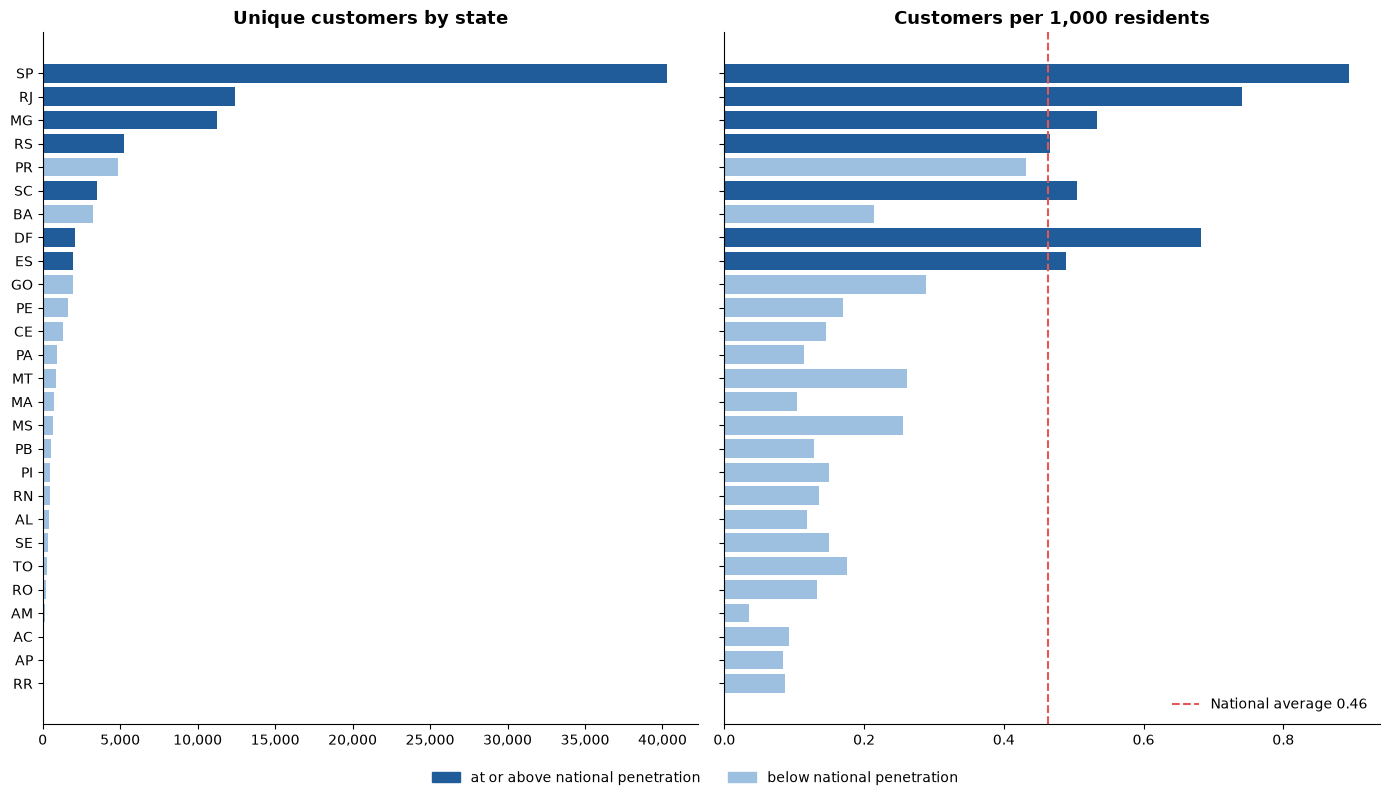

In [14]:
states = (orders_t.groupby("customer_state")
          .agg(customers=("customer_unique_id", "nunique"), orders=("order_id", "size"), revenue=("revenue", "sum")))
states = states.merge(population.set_index("states"), left_index=True, right_index=True, how="left")
states["customers_%"] = states["customers"] / KM["unique_customers"] * 100
states["orders_%"] = states["orders"] / states["orders"].sum() * 100
states["per_1000_residents"] = states["customers"] / states["state_population"] * 1000
states["region"] = states.index.map(REGION_OF_STATE)
states = states.sort_values("customers", ascending=False)
national = states["customers"].sum() / states["state_population"].sum() * 1000
display(states.head(10).round(2))
states.to_csv(config.TABLES_DIR / "customers_by_state.csv")
top5 = states["customers_%"].head(5).sum()
print(f"Top 5 states hold {top5:.2f}% of customers | national penetration: {national:.2f} customers per 1,000 residents")
print(f"Largest gap between order share and customer share: {(states['orders_%'] - states['customers_%']).abs().max():.3f} pp")

s = states.sort_values("customers")
colors = np.where(s["per_1000_residents"] >= national, "#1F5C99", "#9DBFE0")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
ax1.barh(s.index, s["customers"], color=colors); thousands(ax1, "x"); ax1.set_title("Unique customers by state")
ax2.barh(s.index, s["per_1000_residents"], color=colors)
ax2.axvline(national, color=RED, linestyle="--", label=f"National average {national:.2f}")
ax2.set_title("Customers per 1,000 residents"); ax2.legend(loc="lower right")
fig.legend(handles=[Patch(color="#1F5C99", label="at or above national penetration"),
                    Patch(color="#9DBFE0", label="below national penetration")], loc="lower center", ncol=2)
plt.tight_layout(rect=[0, 0.04, 1, 1]); save_fig(fig, "04_customers_by_state"); plt.show()
KM.update({"top5_states_%": float(top5), "sp_customers_%": float(states.loc["SP", "customers_%"]),
           "national_per_1000": float(national), "sp_per_1000": float(states.loc["SP", "per_1000_residents"]),
           "ba_per_1000": float(states.loc["BA", "per_1000_residents"]),
           "am_per_1000": float(states.loc["AM", "per_1000_residents"])})

**Interpretation.**
- **Concentration:** São Paulo alone holds **41.94%** of unique customers, and the five largest states (SP, RJ, MG, RS, PR) hold **77.11%**. At city level, São Paulo city has 15.6% of customers and the top 10 cities 35%.
- **Population-adjusted view:** the national average is **0.46 customers per 1,000 residents**. SP (0.89), RJ, DF, MG, SC and ES are above it. Large north-eastern states such as BA (0.21) have many customers only because of their population, and the North is the weakest (AM 0.04). **Penetration falls sharply outside the South-East**, which is also where delivery is slowest (Section 6).
- **Orders follow customers:** each state's share of orders differs from its share of customers by less than 0.05 percentage points, so no state orders noticeably more or less than its customer base suggests.

In [15]:
region = (orders_t[orders_t["n_items"].notna()].groupby("customer_region")
          .agg(orders=("order_id", "size"), revenue=("revenue", "sum"), aov=("revenue", "mean"),
               freight=("freight", "sum"), product_sales=("product_sales", "sum")))
region["freight_%_of_product_value"] = region["freight"] / region["product_sales"] * 100
region["revenue_%"] = region["revenue"] / region["revenue"].sum() * 100
region = region.sort_values("revenue", ascending=False)
display(region.round(2))
KM["southeast_revenue_%"] = float(region.loc["Southeast", "revenue_%"])
KM["freight_pct_southeast"] = float(region.loc["Southeast", "freight_%_of_product_value"])
KM["freight_pct_north"] = float(region.loc["North", "freight_%_of_product_value"])
KM["freight_pct_northeast"] = float(region.loc["Northeast", "freight_%_of_product_value"])

,orders,revenue,aov,freight,product_sales,freight_%_of_product_value,revenue_%
customer_region,,,,,,,
Southeast,67706,"10,232,323.50",151.13,"1,344,930.44","8,887,393.06",15.13,64.58
South,14042,"2,296,975.80",163.58,"343,034.68","1,953,941.12",17.56,14.50
Northeast,9336,"1,880,799.54",201.46,"335,305.79","1,545,493.75",21.70,11.87
Center-West,5744,"1,023,062.00",178.11,"152,599.94","870,462.06",17.53,6.46
North,1838,"410,392.40",223.28,"76,038.69","334,353.71",22.74,2.59


**Interpretation.** The South-East generates **64.6% of revenue**. Customers in the North and North-East place **larger orders** (AOV R$223 and R$201 vs R$151 in the South-East) but pay much more for shipping: freight equals **22.7% of the product value in the North and 21.7% in the North-East, against 15.1% in the South-East**. Distance from the seller base makes the same purchase more expensive outside the South-East, a likely brake on penetration there.

---
## 5. Product and Payment Analysis

**Goal (sales):** which categories drive demand and sales value? **Goal (finance):** how do customers pay, and is the payment amount related to the installments?

Definitions: *items sold* = rows in `order_items`; *product sales* = `SUM(price)`; payments are analysed at record level **and** order level, never mixed.

Categories: 74 (73 named + 'unknown')


,items_sold,sales,orders,avg_price,sales_%,items_%,rank_items,rank_sales,cumulative_sales_%
product_category_name,,,,,,,,,
health_beauty,9670,"1,258,681.34",8836,130.16,9.26,8.58,2,1,9.26
watches_gifts,5991,"1,205,005.68",5624,201.14,8.87,5.32,7,2,18.13
bed_bath_table,11115,"1,036,988.68",9417,93.30,7.63,9.87,1,3,25.76
sports_leisure,8641,"988,048.97",7720,114.34,7.27,7.67,3,4,33.03
computers_accessories,7827,"911,954.32",6689,116.51,6.71,6.95,5,5,39.74
furniture_decor,8334,"729,762.49",6449,87.56,5.37,7.40,4,6,45.10
cool_stuff,3796,"635,290.85",3632,167.36,4.67,3.37,12,7,49.78
housewares,6964,"632,248.66",5884,90.79,4.65,6.18,6,8,54.43
auto,4235,"592,720.11",3897,139.96,4.36,3.76,10,9,58.79


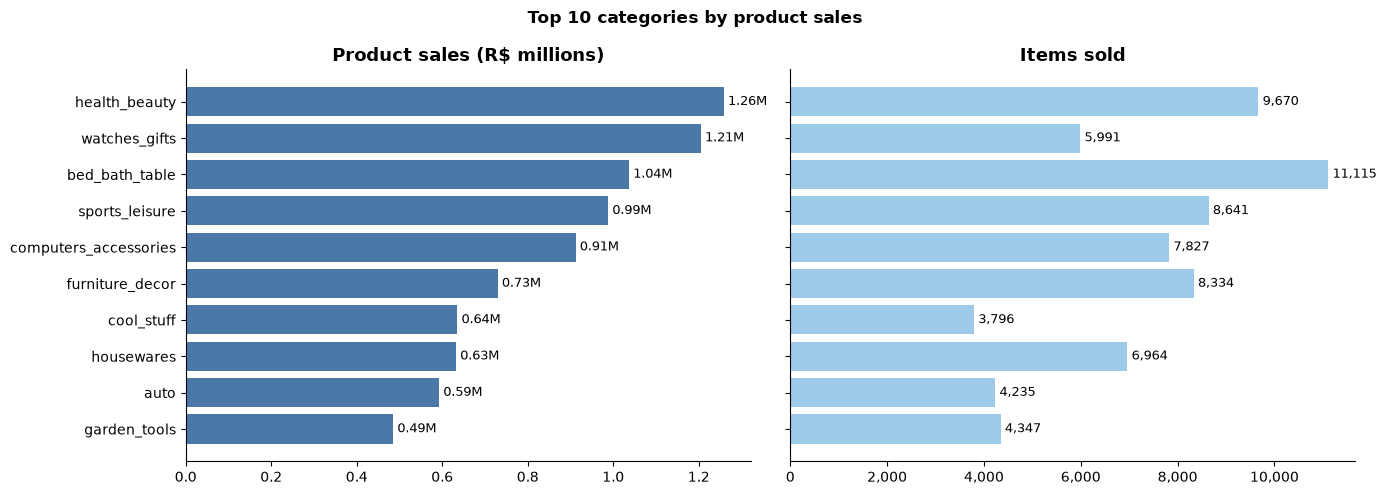

In [16]:
items = tables["order_items_clean"].merge(tables["products_clean"][["product_id", "product_category_name"]],
                                          on="product_id", how="left", validate="many_to_one")
assert len(items) == len(tables["order_items_clean"]) and abs(items["price"].sum() - KM["product_sales"]) < 0.01
cat = items.groupby("product_category_name").agg(items_sold=("price", "size"), sales=("price", "sum"),
                                                 orders=("order_id", "nunique"), avg_price=("price", "mean"))
cat["sales_%"] = cat["sales"] / cat["sales"].sum() * 100
cat["items_%"] = cat["items_sold"] / cat["items_sold"].sum() * 100
cat["rank_items"] = cat["items_sold"].rank(ascending=False, method="min").astype(int)
cat["rank_sales"] = cat["sales"].rank(ascending=False, method="min").astype(int)
cat = cat.sort_values("sales", ascending=False)
cat["cumulative_sales_%"] = cat["sales_%"].cumsum()
print(f"Categories: {len(cat)} (73 named + 'unknown')")
display(cat.head(12).round(2))

top = cat.head(10).iloc[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ax1.barh(top.index, top["sales"] / 1e6, color=BLUE); ax1.set_title("Product sales (R$ millions)")
ax2.barh(top.index, top["items_sold"], color=LIGHT_BLUE); ax2.set_title("Items sold"); thousands(ax2, "x")
for ax, col, fmt in [(ax1, "sales", lambda v: f"{v / 1e6:.2f}M"), (ax2, "items_sold", lambda v: f"{v:,.0f}")]:
    ax.bar_label(ax.containers[0], labels=[fmt(v) for v in top[col]], padding=3, fontsize=9)
fig.suptitle("Top 10 categories by product sales", fontweight="bold")
plt.tight_layout(); save_fig(fig, "05_top_categories"); plt.show()
cat.to_csv(config.TABLES_DIR / "categories.csv")
KM.update({"top5_categories_sales_%": float(cat["sales_%"].head(5).sum()),
           "top10_categories_sales_%": float(cat["sales_%"].head(10).sum()),
           "top_category": cat.index[0], "top_category_sales": float(cat["sales"].iloc[0])})

**Interpretation.**
- **Leaders:** `health_beauty` has the highest product sales (R$1.26M, 9.26%), followed by `watches_gifts` (R$1.21M), `bed_bath_table`, `sports_leisure` and `computers_accessories`. These five make **39.7%** of product sales, and the top 10 make **62.4%**, so sales are spread across many categories rather than dependent on one.
- **Volume vs value:** `bed_bath_table` sells the most items (11,115) but is only 3rd by sales. `watches_gifts` is 7th by items but 2nd by sales (average price R$201), while `telephony` is 8th by items but 14th by sales (average R$71). Ranking by item count alone would misjudge category value.
- Product sales are not profit; margins are not available in the data.

,records,orders,value,avg_value,records_%,value_%
payment_type,,,,,,
credit_card,76795,76505,"12,542,084.19",163.32,73.92,78.34
boleto,19784,19784,"2,869,361.27",145.03,19.04,17.92
voucher,5775,3866,"379,436.87",65.70,5.56,2.37
debit_card,1529,1528,"217,989.79",142.57,1.47,1.36
not_defined,3,3,0.00,0.00,0.00,0.00


Payment records: 103,886 for 99,440 orders | orders with >1 record: 2,961 | orders with >1 method: 2,246


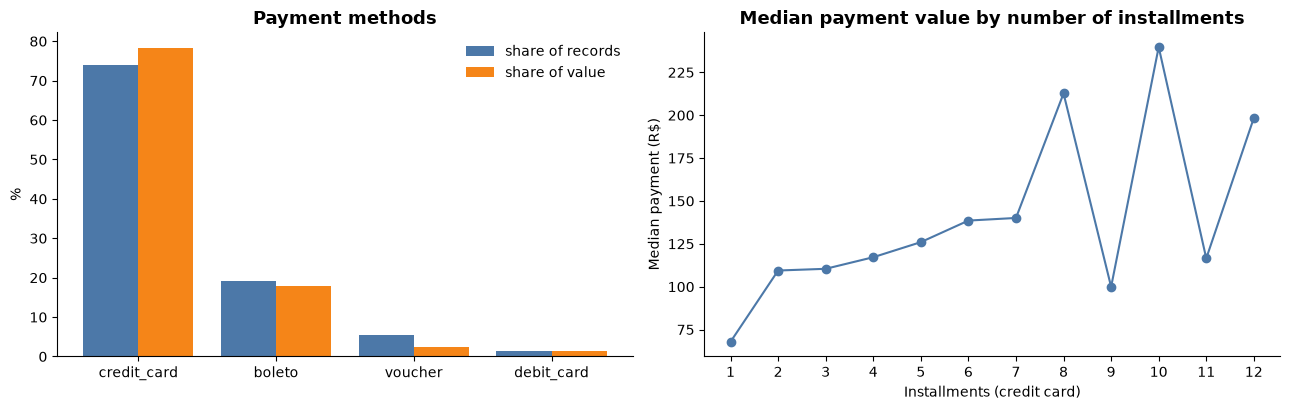

Records paid in 1 installment: 50.58% | credit-card installments: median 3, max 24


In [17]:
pay = tables["payments_clean"]
by_type = pay.groupby("payment_type").agg(records=("order_id", "size"), orders=("order_id", "nunique"),
                                          value=("payment_value", "sum"), avg_value=("payment_value", "mean"))
by_type["records_%"] = by_type["records"] / by_type["records"].sum() * 100
by_type["value_%"] = by_type["value"] / by_type["value"].sum() * 100
by_type = by_type.sort_values("records", ascending=False)
display(by_type.round(2))
per_order = pay.groupby("order_id").agg(n=("payment_sequential", "size"), m=("payment_type", "nunique"))
print(f"Payment records: {len(pay):,} for {pay['order_id'].nunique():,} orders | "
      f"orders with >1 record: {(per_order['n'] > 1).sum():,} | orders with >1 method: {(per_order['m'] > 1).sum():,}")

cc = pay[pay["payment_type"] == "credit_card"].dropna(subset=["payment_installments"])
med = cc.groupby("payment_installments")["payment_value"].median()
one_inst = (pay["payment_installments"] == 1).mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
m = by_type.drop("not_defined")
x = np.arange(len(m))
ax1.bar(x - 0.2, m["records_%"], 0.4, color=BLUE, label="share of records")
ax1.bar(x + 0.2, m["value_%"], 0.4, color=ORANGE, label="share of value")
ax1.set_xticks(x, m.index); ax1.set_ylabel("%"); ax1.legend(); ax1.set_title("Payment methods")
ax2.plot(med.loc[1:12].index.astype(int), med.loc[1:12].values, marker="o", color=BLUE)
ax2.set_xticks(range(1, 13)); ax2.set_xlabel("Installments (credit card)"); ax2.set_ylabel("Median payment (R$)")
ax2.set_title("Median payment value by number of installments")
plt.tight_layout(); save_fig(fig, "05_payments"); plt.show()
print(f"Records paid in 1 installment: {one_inst:.2f}% | credit-card installments: median "
      f"{cc['payment_installments'].median():.0f}, max {cc['payment_installments'].max()}")
KM.update({"credit_card_records_%": float(by_type.loc["credit_card", "records_%"]),
           "credit_card_value_%": float(by_type.loc["credit_card", "value_%"]),
           "boleto_records_%": float(by_type.loc["boleto", "records_%"]),
           "voucher_records_%": float(by_type.loc["voucher", "records_%"]),
           "one_installment_%": float(one_inst),
           "cc_median_installments": float(cc["payment_installments"].median()),
           "orders_multi_payment_records": int((per_order["n"] > 1).sum())})

**Interpretation.**
- **Credit card dominates:** 73.92% of payment records and **78.34% of the amount paid**, with the highest average payment (R$163). *Boleto* (bank slip) is second with 19.04% of records; vouchers (5.56%) are often used as a second payment inside the same order.
- **Records ≠ orders:** 103,886 payment records belong to 99,440 orders; 2,961 orders have several records. Counting records as orders would overstate order volume by 4.5%.
- **Installments:** half of the records (50.6%) are paid at once. Only credit card offers installments (median 3, up to 24). Larger payments are spread over more installments (median R$68 at 1 installment vs R$240 at 10), so installment credit supports higher-value purchases.

---
## 6. Delivery Performance Analysis

**Goal:** measure delivery speed and punctuality, the severity of late deliveries, and how performance differs by state and by month.

**Data:** delivered orders with a customer delivery date (96,470). Delivery time = delivery date − purchase date; *late* = delivered after the estimated date (calendar days).

delivered_orders   96,470.00
mean_days              12.56
median_days            10.22
p90_days               23.10
late_orders         6,534.00
late_rate_%             6.77
on_estimated_day    1,292.00
early_orders       88,644.00
late_over_7_days    2,862.00


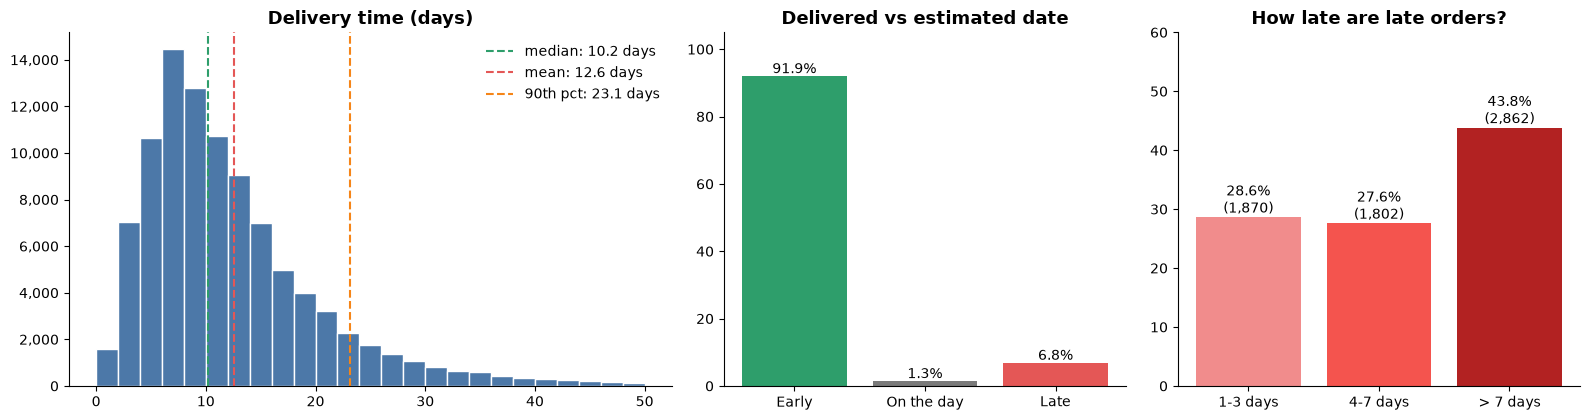

Average / median delay of late orders: 10.6 / 7 days


In [18]:
dl = delivered(orders_t)
dd = dl["delivery_duration_days"]
print(pd.Series(dlv).to_string())
early, ontime, late = dlv["early_orders"], dlv["on_estimated_day"], dlv["late_orders"]
late_df = dl[dl["is_late"].astype(bool)]
sev = pd.cut(late_df["delivery_delay_days"].astype(float), [0, 3, 7, np.inf], labels=["1-3 days", "4-7 days", "> 7 days"])
sev = sev.value_counts().reindex(["1-3 days", "4-7 days", "> 7 days"])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 1]})
cap = 50
ax1.hist(dd[dd <= cap], bins=np.arange(0, cap + 2, 2), color=BLUE, edgecolor="white")
for v, c, lab in [(dd.median(), GREEN, "median"), (dd.mean(), RED, "mean"), (dd.quantile(0.9), ORANGE, "90th pct")]:
    ax1.axvline(v, color=c, linestyle="--", label=f"{lab}: {v:.1f} days")
ax1.set_title("Delivery time (days)"); ax1.legend(); thousands(ax1)
b = ax2.bar(["Early", "On the day", "Late"], np.array([early, ontime, late]) / len(dl) * 100, color=[GREEN, GRAY, RED])
ax2.bar_label(b, fmt="%.1f%%"); ax2.set_title("Delivered vs estimated date"); ax2.set_ylim(0, 105)
b = ax3.bar(sev.index, sev.values / sev.sum() * 100, color=["#F18C8C", "#F4544E", "#B22222"])
ax3.bar_label(b, labels=[f"{p:.1f}%\n({n:,})" for p, n in zip(sev.values / sev.sum() * 100, sev.values)])
ax3.set_title("How late are late orders?"); ax3.set_ylim(0, 60)
plt.tight_layout(); save_fig(fig, "06_delivery_overview"); plt.show()
print(f"Average / median delay of late orders: {late_df['delivery_delay_days'].mean():.1f} / {late_df['delivery_delay_days'].median():.0f} days")
KM.update({"delivered_orders": dlv["delivered_orders"], "delivery_mean_days": dlv["mean_days"],
           "delivery_median_days": dlv["median_days"], "delivery_p90_days": dlv["p90_days"],
           "late_orders": dlv["late_orders"], "late_rate_%": dlv["late_rate_%"],
           "early_rate_%": early / len(dl) * 100, "late_over_7_days": dlv["late_over_7_days"],
           "late_over_7_share_of_late_%": dlv["late_over_7_days"] / late * 100,
           "late_mean_delay": float(late_df["delivery_delay_days"].mean())})

**Interpretation.**
- **Speed:** the median delivery takes **10.2 days**, the mean 12.6 days and 10% of orders take more than **23 days**. The long right tail (maximum 210 days) pulls the average up, so the 90th percentile is the better number for setting customer expectations.
- **Punctuality:** **91.9%** of orders arrive before the estimated date, 1.3% on the day and **6.77% (6,534 orders) late**. Such a high early share suggests the estimates are padded: they protect the late rate but give customers an inaccurate promise.
- **Severity:** late orders are not slightly late. The median delay is 7 days, and **2,862 orders (43.8% of late orders) arrive more than a week late**. These are the cases that damage satisfaction the most (Section 7).

,orders,avg_days,late_rate,late_orders,region
customer_state,,,,,
AL,397,24.54,21.41,85,Northeast
MA,717,21.57,17.43,125,Northeast
SE,335,21.52,15.22,51,Northeast
PI,476,19.46,13.87,66,Northeast
CE,1279,21.27,13.76,176,Northeast
RR,41,29.39,12.20,5,North
BA,3256,19.34,12.16,396,Northeast
RJ,12350,15.31,12.11,1495,Southeast
PA,946,23.77,11.21,106,North


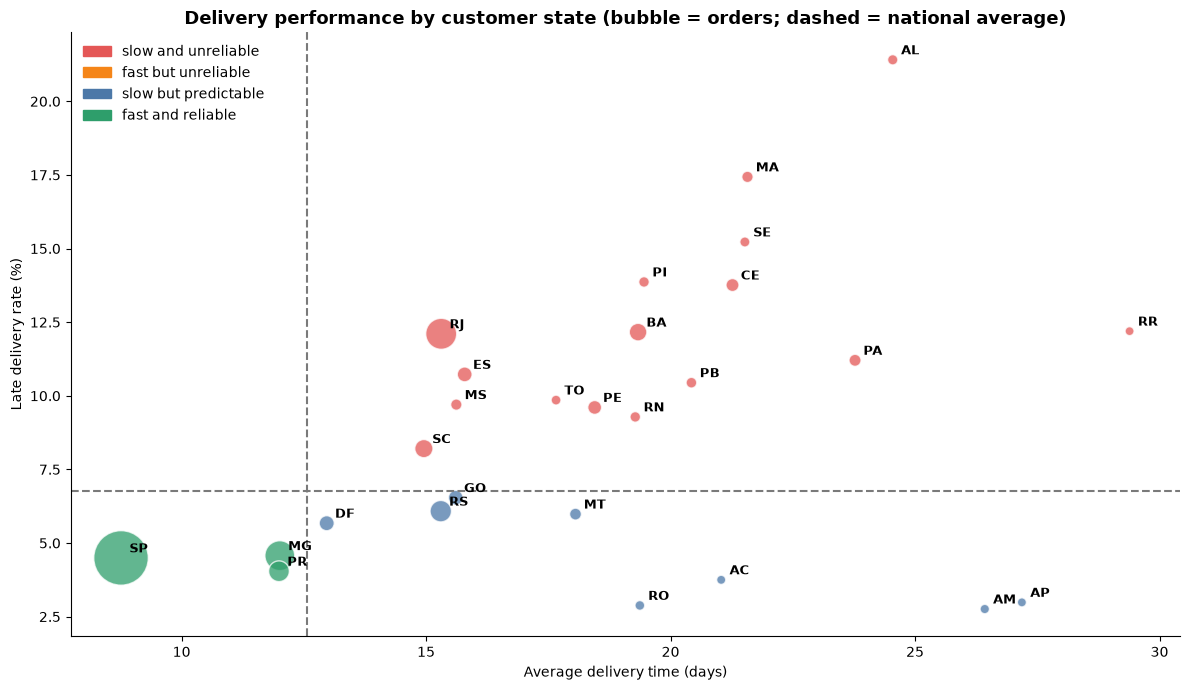

States slow AND unreliable: 16 of 27
SP + RJ share of all late orders: 50.7%


,avg_days,late_rate
customer_region,,
Center-West,15.02,6.53
North,22.59,8.57
Northeast,20.01,12.72
South,14.03,5.90
Southeast,10.75,6.12


In [19]:
st = (dl.groupby("customer_state")
      .agg(orders=("order_id", "size"), avg_days=("delivery_duration_days", "mean"),
           late_rate=("is_late", "mean"), late_orders=("is_late", "sum")))
st["late_rate"] = st["late_rate"].astype(float) * 100
st["region"] = st.index.map(REGION_OF_STATE)
st = st.sort_values("late_rate", ascending=False)
st.to_csv(config.TABLES_DIR / "delivery_by_state.csv")
vx, vy = dlv["mean_days"], dlv["late_rate_%"]
display(st.head(10).round(2))

fig, ax = plt.subplots(figsize=(12, 7))
zone = np.select([(st["avg_days"] > vx) & (st["late_rate"] > vy), st["late_rate"] > vy, st["avg_days"] > vx],
                 ["slow and unreliable", "fast but unreliable", "slow but predictable"], "fast and reliable")
zc = {"slow and unreliable": RED, "fast but unreliable": ORANGE, "slow but predictable": BLUE, "fast and reliable": GREEN}
ax.scatter(st["avg_days"], st["late_rate"], s=40 + st["orders"] / st["orders"].max() * 1500,
           c=[zc[z] for z in zone], alpha=0.75, edgecolor="white")
for s_, r in st.iterrows():
    ax.annotate(s_, (r["avg_days"], r["late_rate"]), xytext=(6, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.axvline(vx, color=GRAY, linestyle="--"); ax.axhline(vy, color=GRAY, linestyle="--")
ax.set_xlabel("Average delivery time (days)"); ax.set_ylabel("Late delivery rate (%)")
ax.set_title("Delivery performance by customer state (bubble = orders; dashed = national average)")
ax.legend(handles=[Patch(color=c, label=z) for z, c in zc.items()], loc="upper left")
plt.tight_layout(); save_fig(fig, "06_delivery_by_state"); plt.show()

sp_rj = st.loc[["SP", "RJ"], "late_orders"].sum() / dlv["late_orders"] * 100
print(f"States slow AND unreliable: {(zone == 'slow and unreliable').sum()} of {len(st)}")
print(f"SP + RJ share of all late orders: {sp_rj:.1f}%")
reg = dl.groupby("customer_region").agg(avg_days=("delivery_duration_days", "mean"), late_rate=("is_late", "mean"))
reg["late_rate"] = reg["late_rate"].astype(float) * 100
display(reg.round(2))
KM.update({"al_late_%": float(st.loc["AL", "late_rate"]), "sp_late_%": float(st.loc["SP", "late_rate"]),
           "sp_days": float(st.loc["SP", "avg_days"]), "rj_late_%": float(st.loc["RJ", "late_rate"]),
           "ma_late_%": float(st.loc["MA", "late_rate"]), "rr_days": float(st.loc["RR", "avg_days"]),
           "sp_rj_late_share_%": float(sp_rj),
           "northeast_late_%": float(reg.loc["Northeast", "late_rate"]), "northeast_days": float(reg.loc["Northeast", "avg_days"]),
           "southeast_late_%": float(reg.loc["Southeast", "late_rate"]), "southeast_days": float(reg.loc["Southeast", "avg_days"]),
           "north_days": float(reg.loc["North", "avg_days"])})

**Interpretation.**
- **Delivery problems are regional.** SP is the benchmark (8.8 days, 4.5% late). The North-East combines slow delivery with the highest late rates: **AL 21.4%**, MA 17.4%, SE 15.2%, PI and CE about 14%. The North is the slowest region (22.6 days on average, RR 29 days), but several northern states (AM, AP, AC, RO) are rarely late because their estimates already include the long transit.
- **Rates vs counts:** RJ has a 12.1% late rate on a very large volume, so **SP and RJ together produce about half of all late orders** even though SP's rate is low. Fixing RJ reaches the most customers; fixing AL, MA, SE and CE reduces the worst experiences.

,orders,avg_days,late_rate,score
purchase_month,,,,
2017-01-01,750,12.65,2.93,4.20
2017-02-01,1653,13.17,2.96,4.20
2017-03-01,2546,12.95,4.56,4.19
2017-04-01,2303,14.92,6.56,4.14
2017-05-01,3545,11.32,2.99,4.24
2017-06-01,3135,12.01,3.03,4.22
2017-07-01,3872,11.59,2.79,4.26
2017-08-01,4193,11.15,2.91,4.31
2017-09-01,4150,11.85,4.39,4.27


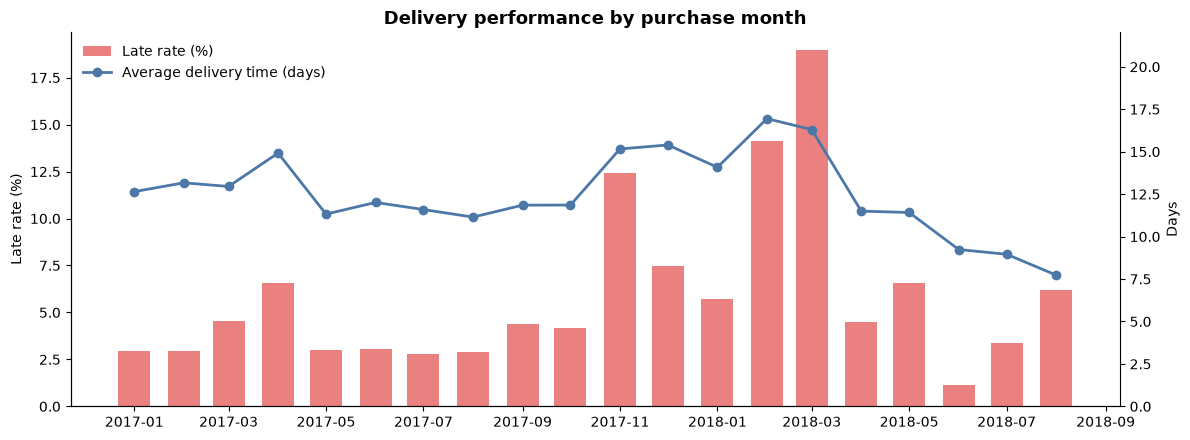

In [20]:
dm = (dl.groupby("purchase_month")
      .agg(orders=("order_id", "size"), avg_days=("delivery_duration_days", "mean"), late_rate=("is_late", "mean"),
           score=("review_score", "mean")))
dm["late_rate"] = dm["late_rate"].astype(float) * 100
dm = dm.loc[VALID_START:VALID_END]
display(dm.round(2))
dm.to_csv(config.TABLES_DIR / "delivery_by_month.csv")

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(dm.index, dm["late_rate"], width=20, color=RED, alpha=0.75, label="Late rate (%)")
ax1.set_ylabel("Late rate (%)")
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(dm.index, dm["avg_days"], color=BLUE, marker="o", linewidth=2, label="Average delivery time (days)")
ax2.set_ylabel("Days"); ax2.set_ylim(0, dm["avg_days"].max() * 1.3)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left"); ax1.set_title("Delivery performance by purchase month")
plt.tight_layout(); save_fig(fig, "06_delivery_by_month"); plt.show()
KM.update({"mar18_late_%": float(dm.loc["2018-03-01", "late_rate"]), "feb18_late_%": float(dm.loc["2018-02-01", "late_rate"]),
           "nov17_late_%": float(dm.loc["2017-11-01", "late_rate"]), "jun18_late_%": float(dm.loc["2018-06-01", "late_rate"]),
           "aug18_days": float(dm.loc["2018-08-01", "avg_days"]), "feb18_days": float(dm.loc["2018-02-01", "avg_days"]),
           "jan18_late_%": float(dm.loc["2018-01-01", "late_rate"]),
           "mar18_score": float(dm.loc["2018-03-01", "score"])})

**Interpretation.** Delivery reliability broke down twice: in **November 2017** (Black Friday, 12.4% late) and, more severely, in **February–March 2018 (14.1% and 19.0% late; 16.9 days average delivery in February)**. Volume alone does not explain March: January 2018 had almost the same volume but only 5.7% late orders, which points to carrier or capacity problems in that period. Customers noticed: the average review score of orders bought in March 2018 fell to **3.81**, against 4.2–4.3 in normal months. Performance recovered strongly from April 2018 (7.7 days on average in August), showing that much better service is achievable.

---
## 7. Review and Customer Satisfaction Analysis

**Goal:** measure overall satisfaction, find the categories with low satisfaction, and test how delivery performance relates to review scores.

**Definition:** one score per order, the latest answered review (98,673 reviewed orders). The score belongs to the whole order, not to a single product or seller.

Reviewed orders: 98,673 (99.23% of orders) | average score: 4.09
Positive (4-5): 77.07% | neutral (3): 8.24% | negative (1-2): 14.69%


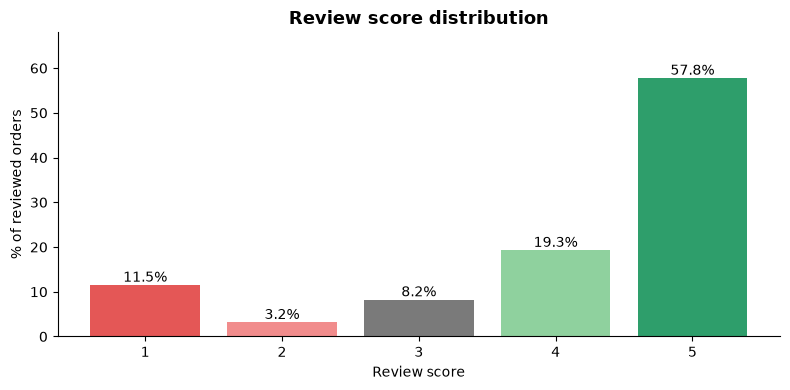

In [21]:
rv = orders_t[orders_t["review_score"].notna()]
dist = rv["review_score"].value_counts().sort_index()
dist_pct = dist / dist.sum() * 100
print(f"Reviewed orders: {len(rv):,} ({len(rv) / len(orders_t):.2%} of orders) | average score: {rv['review_score'].mean():.2f}")
print(f"Positive (4-5): {(rv['review_score'] >= 4).mean():.2%} | neutral (3): {(rv['review_score'] == 3).mean():.2%} | "
      f"negative (1-2): {rv['is_negative_review'].mean():.2%}")

fig, ax = plt.subplots(figsize=(8, 4))
b = ax.bar(dist.index.astype(int).astype(str), dist_pct, color=[RED, "#F18C8C", GRAY, "#8FD19E", GREEN])
ax.bar_label(b, fmt="%.1f%%"); ax.set_xlabel("Review score"); ax.set_ylabel("% of reviewed orders")
ax.set_title("Review score distribution"); ax.set_ylim(0, 68)
plt.tight_layout(); save_fig(fig, "07_review_distribution"); plt.show()
KM.update({"reviewed_orders": len(rv), "avg_score": float(rv["review_score"].mean()),
           "positive_%": float((rv["review_score"] >= 4).mean() * 100), "negative_%": float(rv["is_negative_review"].mean() * 100),
           "one_star_%": float(dist_pct.loc[1])})

**Interpretation.** The average score of **4.09** and 77% positive reviews look healthy, but the distribution is polarized: **1 star (11.5%) is more common than 2 or 3 stars**, and **14.7% of reviewed orders are negative**. The negative rate is a better management KPI than the average, because a small change in the average can hide a large change in the number of very unhappy customers.

,orders,avg_score,negative_rate
delay_group,,,
on time / early,89443,4.29,9.27
1-3 days late,1852,3.29,32.13
4-7 days late,1748,2.10,67.68
> 7 days late,2781,1.70,79.29


On-time: 4.29 | late: 2.27
Late orders are 6.7% of reviewed delivered orders but 32.5% of their negative reviews


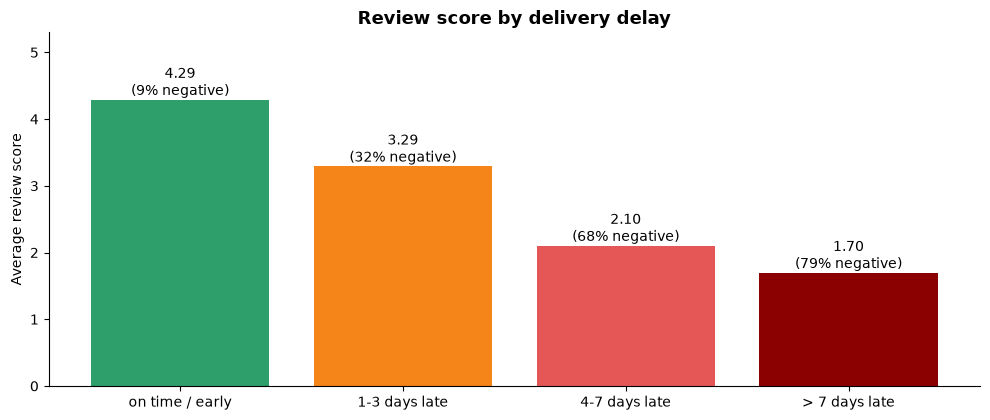

In [22]:
d7 = dl[dl["review_score"].notna()].copy()
d7["delay_group"] = pd.cut(d7["delivery_delay_days"].astype(float), [-np.inf, 0, 3, 7, np.inf],
                           labels=["on time / early", "1-3 days late", "4-7 days late", "> 7 days late"])
by_delay = d7.groupby("delay_group", observed=True).agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                                        negative_rate=("is_negative_review", "mean"))
by_delay["negative_rate"] = by_delay["negative_rate"].astype(float) * 100
display(by_delay.round(2))

late_mask = d7["is_late"].astype(bool)
neg_mask = d7["is_negative_review"].astype(bool)
late_share_of_neg = (late_mask & neg_mask).sum() / neg_mask.sum() * 100
print(f"On-time: {d7.loc[~late_mask, 'review_score'].mean():.2f} | late: {d7.loc[late_mask, 'review_score'].mean():.2f}")
print(f"Late orders are {late_mask.mean():.1%} of reviewed delivered orders but {late_share_of_neg:.1f}% of their negative reviews")

fig, ax = plt.subplots(figsize=(10, 4.3))
b = ax.bar(by_delay.index.astype(str), by_delay["avg_score"], color=[GREEN, ORANGE, RED, "#8B0000"])
ax.bar_label(b, labels=[f"{s:.2f}\n({n:.0f}% negative)" for s, n in zip(by_delay["avg_score"], by_delay["negative_rate"])])
ax.set_ylim(0, 5.3); ax.set_ylabel("Average review score"); ax.set_title("Review score by delivery delay")
plt.tight_layout(); save_fig(fig, "07_score_by_delay"); plt.show()
KM.update({"score_ontime": float(by_delay.loc["on time / early", "avg_score"]),
           "score_late": float(d7.loc[late_mask, "review_score"].mean()),
           "score_late_1_3": float(by_delay.loc["1-3 days late", "avg_score"]),
           "score_late_4_7": float(by_delay.loc["4-7 days late", "avg_score"]),
           "score_late_7plus": float(by_delay.loc["> 7 days late", "avg_score"]),
           "neg_ontime_%": float(by_delay.loc["on time / early", "negative_rate"]),
           "neg_late_%": float(d7.loc[late_mask, "is_negative_review"].astype(float).mean() * 100),
           "neg_late_7plus_%": float(by_delay.loc["> 7 days late", "negative_rate"]),
           "late_share_reviewed_%": float(late_mask.mean() * 100), "late_share_of_negative_%": float(late_share_of_neg)})

**Interpretation.** Delivery delay is the strongest pattern in the whole analysis.
- On-time orders average **4.29** with 9.3% negative reviews; late orders average **2.27** with **62.4% negative**.
- The damage grows with the delay: 3.29 after 1–3 days, 2.10 after 4–7 days and **1.70 after more than a week (79% negative)**.
- Late orders are only 6.7% of reviewed deliveries but produce **about a third (32.5%) of all negative reviews** of delivered orders. Reducing severe delays is the most direct lever on satisfaction.

Categories with >= 100 reviewed orders: 52 of 74 | average over category rows: 4.10
High-volume categories (>= 1,000 reviewed orders) below the average score:


,reviewed_orders,avg_score,negative_rate,sales
product_category_name,,,,
bed_bath_table,9313,3.97,16.76,"1,036,988.68"
computers_accessories,6649,4.03,16.09,"911,954.32"
furniture_decor,6398,4.01,16.68,"729,762.49"
watches_gifts,5576,4.07,15.21,"1,205,005.68"
telephony,4168,4.00,15.48,"323,667.53"
auto,3877,4.09,14.50,"592,720.11"
baby,2861,4.04,16.01,"411,764.89"
electronics,2531,4.10,14.07,"160,246.74"
unknown,1439,3.91,20.08,"179,535.28"


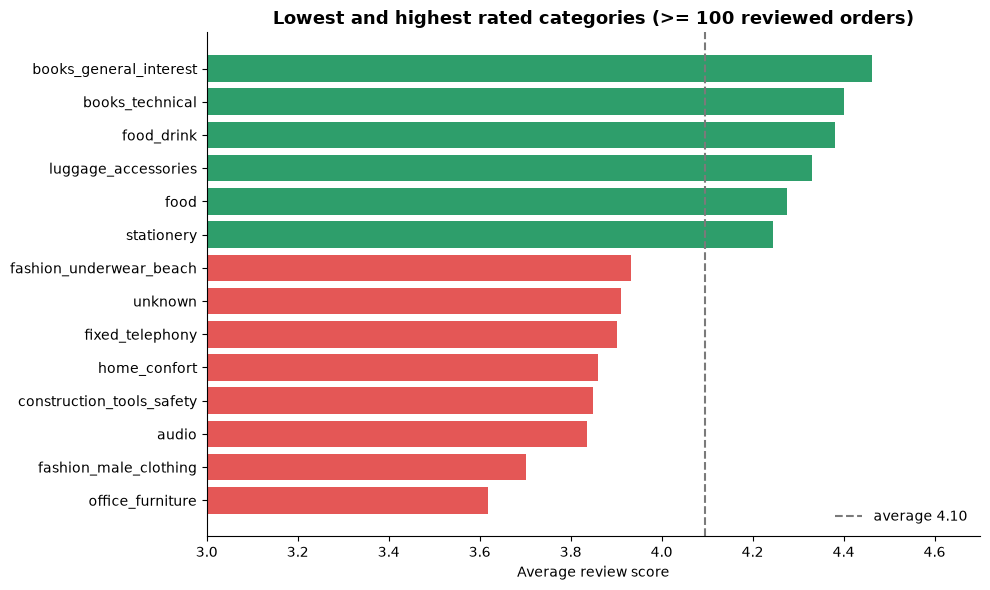

In [23]:
cat_orders = (tables["order_items_clean"][["order_id", "product_id"]]
              .merge(tables["products_clean"][["product_id", "product_category_name"]], on="product_id")
              [["order_id", "product_category_name"]].drop_duplicates())          # one row per (order, category)
cat_rev = cat_orders.merge(orders_t[["order_id", "review_score", "is_negative_review"]], on="order_id")
cat_rev = cat_rev[cat_rev["review_score"].notna()]
cs = cat_rev.groupby("product_category_name").agg(reviewed_orders=("order_id", "size"),
                                                  avg_score=("review_score", "mean"),
                                                  negative_rate=("is_negative_review", "mean"))
cs["negative_rate"] = cs["negative_rate"].astype(float) * 100
cs = cs.join(cat[["sales"]])
reliable = cs[cs["reviewed_orders"] >= 100].sort_values("avg_score")
avg_all = cat_rev["review_score"].mean()
print(f"Categories with >= 100 reviewed orders: {len(reliable)} of {len(cs)} | average over category rows: {avg_all:.2f}")
hs_ls = reliable[(reliable["reviewed_orders"] >= 1000) & (reliable["avg_score"] < avg_all)].sort_values("reviewed_orders", ascending=False)
print("High-volume categories (>= 1,000 reviewed orders) below the average score:")
display(hs_ls.round(2))

show = pd.concat([reliable.head(8), reliable.tail(6)])
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(show.index, show["avg_score"], color=[RED] * 8 + [GREEN] * 6)
ax.axvline(avg_all, color=GRAY, linestyle="--", label=f"average {avg_all:.2f}")
ax.set_xlim(3, 4.7); ax.set_xlabel("Average review score"); ax.legend(loc="lower right")
ax.set_title("Lowest and highest rated categories (>= 100 reviewed orders)")
plt.tight_layout(); save_fig(fig, "07_category_scores"); plt.show()
cs.to_csv(config.TABLES_DIR / "category_satisfaction.csv")
KM.update({"office_furniture_score": float(cs.loc["office_furniture", "avg_score"]),
           "bed_bath_score": float(cs.loc["bed_bath_table", "avg_score"]),
           "best_category": reliable.index[-1], "best_category_score": float(reliable["avg_score"].iloc[-1])})

**Interpretation.** Among categories with at least 100 reviewed orders, scores range from **3.62 (`office_furniture`)** to 4.46 (`books_general_interest`). Small categories are not ranked because a few reviews move their averages a lot. Several large categories combine high volume with below-average satisfaction: **`bed_bath_table`** (the category with the most orders, 3.97), `furniture_decor`, `computers_accessories`, `telephony`, `office_furniture` and `unknown` (products without a category, also a data-quality issue). Bulky products (furniture, bedding) are over-represented among them.

In [24]:
cmp = d7.merge(cat_orders, on="order_id")
cc_ = cmp.groupby(["product_category_name", cmp["is_late"].astype(bool)])["review_score"].agg(["mean", "size"]).unstack()
cc_.columns = ["on_time_score", "late_score", "on_time_n", "late_n"]
cc_ = cc_[cc_["late_n"] >= 50]
cc_["drop"] = cc_["on_time_score"] - cc_["late_score"]
print(f"Categories with >= 50 late reviewed orders: {len(cc_)} | late orders score lower in {(cc_['drop'] > 0).sum()} of them")
print(f"Score drop from on-time to late: {cc_['drop'].min():.2f} to {cc_['drop'].max():.2f} points")

Categories with >= 50 late reviewed orders: 22 | late orders score lower in 22 of them
Score drop from on-time to late: 1.40 to 2.25 points


**Interpretation.** The delivery effect is not driven by a few categories: in **every one of the 22 categories** with enough late orders, late orders score 1.40 to 2.25 points lower. When an order is late, customers are unhappy regardless of what they bought. `office_furniture` is the exception worth a separate look: it scores low even when delivered on time.

---
## 8. Seller Performance Analysis

**Goal:** understand how sales are distributed among sellers, whether Olist depends on a few of them, and whether large sellers keep customers satisfied.

Seller sales = `SUM(price)` of their items. A review belongs to the whole order, so the order's score is assigned to every seller with items in it (each seller–order pair counted once).

Sellers: 3,095 in 23 states | SP: 59.74% | SP+PR+MG: 78.90%
Top 10 sellers: 13.15% of sales | top 100: 45.06% | sellers for 50% of sales: 130 (4.2%) | for 80%: 544 (17.6%)
Largest seller: 1.69% of sales | mean sales R$4,391 vs median R$821


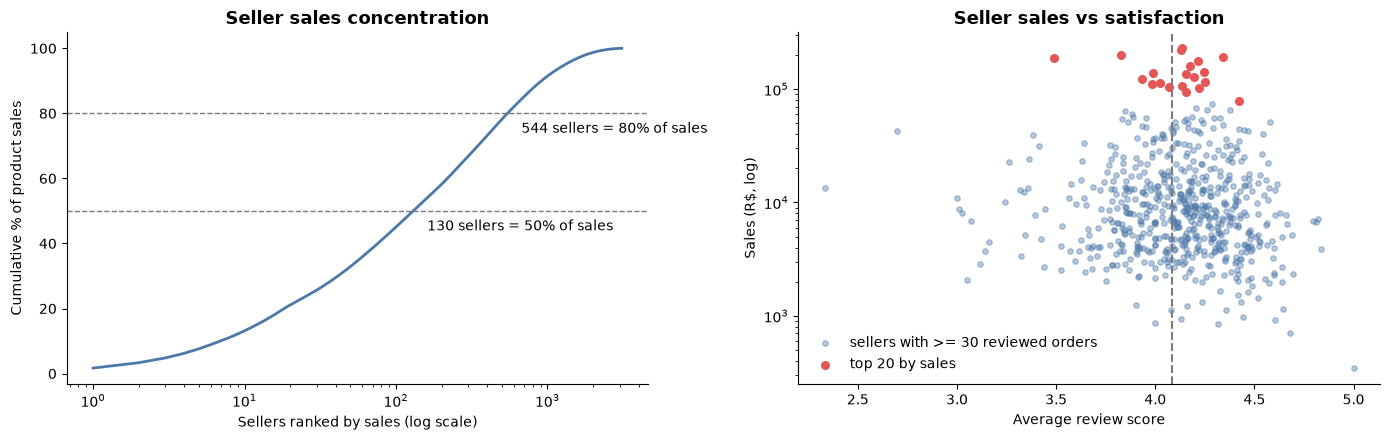

Sellers with >= 30 reviewed orders: 628 (76.6% of sales)


In [25]:
sellers = tables["sellers_clean"]
share_state = sellers["seller_state"].value_counts(normalize=True) * 100
print(f"Sellers: {len(sellers):,} in {sellers['seller_state'].nunique()} states | SP: {share_state['SP']:.2f}% | "
      f"SP+PR+MG: {share_state[['SP', 'PR', 'MG']].sum():.2f}%")

ss = tables["order_items_clean"].groupby("seller_id").agg(items=("price", "size"), sales=("price", "sum"),
                                                          orders=("order_id", "nunique"))
assert abs(ss["sales"].sum() - KM["product_sales"]) < 0.01
so = tables["order_items_clean"][["seller_id", "order_id"]].drop_duplicates().merge(
    orders_t[["order_id", "review_score", "is_late", "is_delivered"]], on="order_id", how="left")
ss = ss.join(so.groupby("seller_id").agg(reviewed_orders=("review_score", "count"), avg_score=("review_score", "mean")))
ss = ss.sort_values("sales", ascending=False)
cum = ss["sales"].cumsum() / ss["sales"].sum() * 100
n50, n80 = int((cum < 50).sum() + 1), int((cum < 80).sum() + 1)
print(f"Top 10 sellers: {cum.iloc[9]:.2f}% of sales | top 100: {cum.iloc[99]:.2f}% | "
      f"sellers for 50% of sales: {n50} ({n50 / len(ss):.1%}) | for 80%: {n80} ({n80 / len(ss):.1%})")
print(f"Largest seller: {ss['sales'].iloc[0] / ss['sales'].sum():.2%} of sales | mean sales R${ss['sales'].mean():,.0f} vs median R${ss['sales'].median():,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(np.arange(1, len(cum) + 1), cum.values, color=BLUE, linewidth=2)
for p, n in [(50, n50), (80, n80)]:
    ax1.axhline(p, color=GRAY, linestyle="--", linewidth=1); ax1.annotate(f"{n} sellers = {p}% of sales", (n, p),
                                                                         xytext=(10, -14), textcoords="offset points")
ax1.set_xscale("log"); ax1.set_xlabel("Sellers ranked by sales (log scale)"); ax1.set_ylabel("Cumulative % of product sales")
ax1.set_title("Seller sales concentration")
enough = ss[ss["reviewed_orders"] >= 30]
ax2.scatter(enough["avg_score"], enough["sales"], alpha=0.4, color=BLUE, s=15, label="sellers with >= 30 reviewed orders")
top20 = enough.head(20)
ax2.scatter(top20["avg_score"], top20["sales"], color=RED, s=30, label="top 20 by sales")
ax2.axvline(KM["avg_score"], color=GRAY, linestyle="--"); ax2.set_yscale("log")
ax2.set_xlabel("Average review score"); ax2.set_ylabel("Sales (R$, log)"); ax2.legend(loc="lower left")
ax2.set_title("Seller sales vs satisfaction")
plt.tight_layout(); save_fig(fig, "08_sellers"); plt.show()
print(f"Sellers with >= 30 reviewed orders: {len(enough)} ({enough['sales'].sum() / ss['sales'].sum():.1%} of sales)")
KM.update({"sellers_sp_%": float(share_state["SP"]), "top10_sellers_%": float(cum.iloc[9]),
           "top100_sellers_%": float(cum.iloc[99]), "sellers_for_50_%": n50, "sellers_for_80_%": n80,
           "sellers_for_50_share_%": n50 / len(ss) * 100})

**Interpretation.**
- **Supply is concentrated in São Paulo:** about 60% of the 3,095 sellers are in SP, and SP, PR and MG together hold almost 80%. This is the root of the long delivery distances to the North and North-East (Section 9).
- **No single-seller risk, but a concentrated core:** the largest seller makes less than 1.7% of sales and the top 10 make 13%. However, about **130 sellers (4.2%) make half of all sales** and the top 100 make 45%. The typical seller is small (median R$821 vs mean R$4,391).
- **Size does not predict satisfaction:** the scatter plot shows no clear pattern between sales and average score, so some large sellers keep customers happy and others do not.

In [26]:
high = enough[enough["sales"] >= enough["sales"].quantile(0.9)]
flag = high[(high["avg_score"] <= KM["avg_score"] - 0.2) & (high["reviewed_orders"] >= 100)].copy()
flag["late_rate_%"] = so[so["is_delivered"] == True].groupby("seller_id")["is_late"].mean().reindex(flag.index).astype(float) * 100
flag.index = flag.index.str[:8]
print(f"High-sales sellers (top 10% of sellers with >= 30 reviewed orders, sales >= R${enough['sales'].quantile(0.9):,.0f}): {len(high)}")
print("High-sales sellers at least 0.2 points below the average score, with >= 100 reviewed orders:")
display(flag.round(2))
print(f"Their share of product sales: {flag['sales'].sum() / ss['sales'].sum():.2%}")
KM.update({"flagged_sellers": len(flag), "flagged_sellers_sales_%": float(flag["sales"].sum() / ss["sales"].sum() * 100)})

High-sales sellers (top 10% of sellers with >= 30 reviewed orders, sales >= R$37,095): 63
High-sales sellers at least 0.2 points below the average score, with >= 100 reviewed orders:


,items,sales,orders,reviewed_orders,avg_score,late_rate_%
seller_id,,,,,,
4a3ca931,1987,"200,472.92",1806,1785,3.83,9.71
7c67e144,1364,"187,923.89",982,976,3.49,9.15
cca3071e,830,"64,009.89",712,700,3.85,4.86
25c5c91f,269,"54,679.22",158,157,3.83,7.05
2eb70248,212,"42,628.61",202,198,2.70,11.23


Their share of product sales: 4.04%


**Interpretation.** Five high-sales sellers are clearly below the average score with enough reviews to be reliable. Two of them are among the five largest sellers on the platform. They make about 4% of product sales, so improving them (or their logistics) protects revenue and many customers at once. Their late rates help separate delivery problems from product or service problems.

---
## 9. Advanced Multi-table Analysis

**Goal:** answer questions that need several tables at once: **why** are orders late, does distance between seller and customer matter, do complex orders satisfy customers less, and does a bad first experience stop customers from coming back?

Tables combined: `orders`, `order_items`, `sellers`, `customers`, `geolocation_prefix`, `products` and `reviews` (through the order table). Row counts are checked after every join.

### 9.1 Who causes late deliveries? Seller handover vs the shipping deadline

Each item has a `shipping_limit_date`: the deadline for the seller to hand the item to the carrier. Comparing it with `order_delivered_carrier_date` separates the **seller's** part of a delay from the **carrier's** part.

Delivered orders with a valid carrier date: 96,281 (of 96,470)


,orders,late_rate,avg_days,avg_score,negative_rate,share_of_orders_%
seller_late_handover,,,,,,
False,87585,5.39,11.87,4.20,11.73,90.97
True,8696,20.86,19.61,3.70,23.70,9.03


Orders with a late seller handover are 3.9x more likely to reach the customer late; they account for 27.8% of all late deliveries


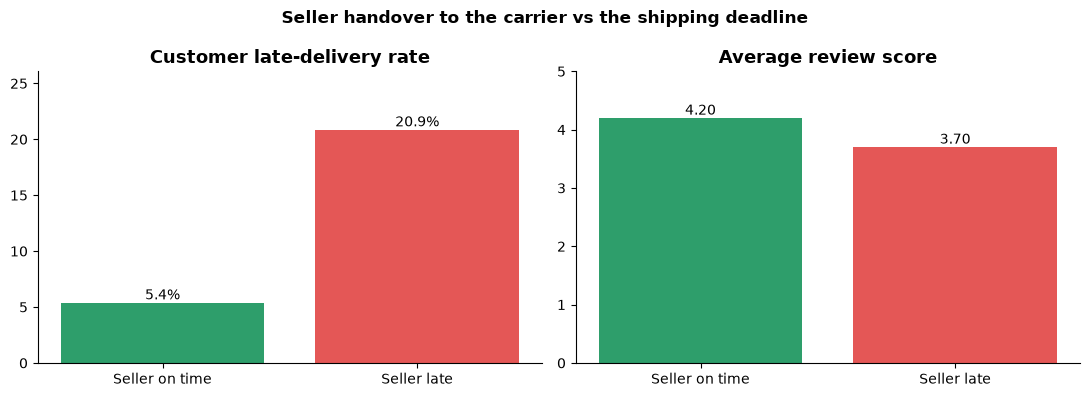

Carrier transit (carrier -> customer), median: 7.1 days | late orders: 26.2 days


In [27]:
h = dl[dl["order_delivered_carrier_date"].notna() & ~dl["flag_carrier_before_purchase"]].copy()
h["seller_late_handover"] = h["order_delivered_carrier_date"] > h["shipping_limit_date"]
print(f"Delivered orders with a valid carrier date: {len(h):,} (of {len(dl):,})")
hh = h.groupby("seller_late_handover").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                                           avg_days=("delivery_duration_days", "mean"), avg_score=("review_score", "mean"),
                                           negative_rate=("is_negative_review", "mean"))
hh[["late_rate", "negative_rate"]] = hh[["late_rate", "negative_rate"]].astype(float) * 100
hh["share_of_orders_%"] = hh["orders"] / hh["orders"].sum() * 100
display(hh.round(2))
late_from_seller = (h["seller_late_handover"] & h["is_late"].astype(bool)).sum() / h["is_late"].astype(bool).sum() * 100
ratio = hh.loc[True, "late_rate"] / hh.loc[False, "late_rate"]
print(f"Orders with a late seller handover are {ratio:.1f}x more likely to reach the customer late; "
      f"they account for {late_from_seller:.1f}% of all late deliveries")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["Seller on time", "Seller late"]
b = axes[0].bar(labels, hh["late_rate"].values, color=[GREEN, RED]); axes[0].bar_label(b, fmt="%.1f%%")
axes[0].set_title("Customer late-delivery rate"); axes[0].set_ylim(0, hh["late_rate"].max() * 1.25)
b = axes[1].bar(labels, hh["avg_score"].values, color=[GREEN, RED]); axes[1].bar_label(b, fmt="%.2f")
axes[1].set_title("Average review score"); axes[1].set_ylim(0, 5)
fig.suptitle("Seller handover to the carrier vs the shipping deadline", fontweight="bold")
plt.tight_layout(); save_fig(fig, "09_seller_handover"); plt.show()

# carrier part: how long carriers take once the seller has shipped
print(f"Carrier transit (carrier -> customer), median: {h['carrier_to_customer_days'].median():.1f} days | "
      f"late orders: {h.loc[h['is_late'].astype(bool), 'carrier_to_customer_days'].median():.1f} days")
KM.update({"seller_late_handover_%": float(hh.loc[True, "share_of_orders_%"]),
           "late_rate_seller_late_%": float(hh.loc[True, "late_rate"]),
           "late_rate_seller_ok_%": float(hh.loc[False, "late_rate"]), "seller_late_ratio": float(ratio),
           "late_from_seller_%": float(late_from_seller),
           "score_seller_late": float(hh.loc[True, "avg_score"]), "score_seller_ok": float(hh.loc[False, "avg_score"])})

**Interpretation.** In about **9% of delivered orders the seller handed the parcel to the carrier after the shipping deadline**. These orders reach the customer late **20.9% of the time, against 5.4%** when the seller ships on time (3.9x), and they score 3.70 instead of 4.20. Late seller handovers explain **about 28% of all late deliveries**; the rest comes from carrier transit, which is much longer for late orders. Delays therefore have two owners, sellers and carriers, and both can be measured with existing data.

### 9.2 Distance between seller and customer
For orders with a single seller, the seller and customer ZIP prefixes are placed on the map with `geolocation_prefix` (median coordinates) and the straight-line distance is computed.

Single-seller delivered orders: 95,195 | with both coordinates: 94,724
Shipped across state borders: 64.0% | median distance: 434 km


,orders,median_days,late_rate,avg_score,freight_%_of_price
distance_km,,,,,
< 100 km,17691,5.10,4.51,4.29,11.71
100-500,36462,9.39,6.18,4.20,15.57
"500-1,000",25388,12.18,7.21,4.13,17.58
"1,000-2,000",9610,15.40,9.60,4.07,19.17
"> 2,000 km",5573,18.30,12.08,3.99,22.70


,avg_days,late_rate,avg_score
same_state,,,
False,15.21,8.14,4.11
True,7.97,4.56,4.28


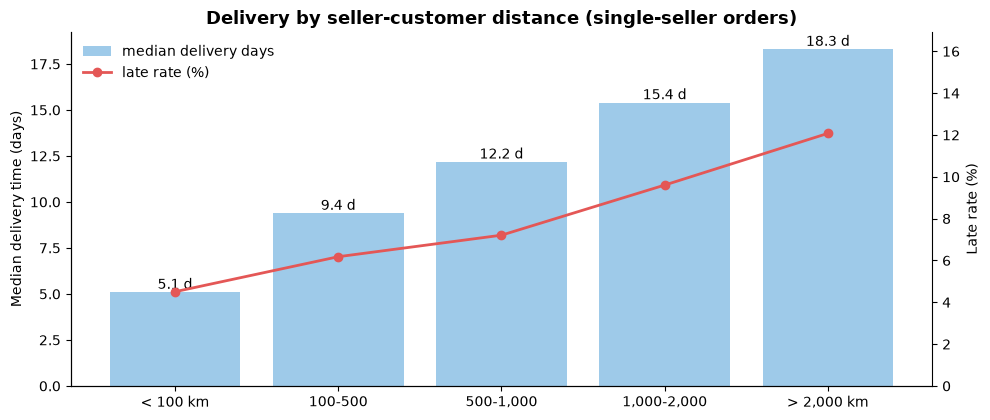

In [28]:
geo = tables["geolocation_prefix"][["geolocation_zip_code_prefix", "lat", "lng"]]
one_seller = dl[dl["n_sellers"] == 1][["order_id", "customer_state", "customer_zip_code_prefix", "delivery_duration_days",
                                        "is_late", "review_score", "freight", "product_sales"]]
first_item = tables["order_items_clean"].drop_duplicates("order_id")[["order_id", "seller_id"]]
x = (one_seller.merge(first_item, on="order_id", how="left", validate="one_to_one")
     .merge(tables["sellers_clean"][["seller_id", "seller_state", "seller_zip_code_prefix"]], on="seller_id", how="left")
     .merge(geo.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix", "lat": "s_lat", "lng": "s_lng"}),
            on="seller_zip_code_prefix", how="left")
     .merge(geo.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix", "lat": "c_lat", "lng": "c_lng"}),
            on="customer_zip_code_prefix", how="left"))
assert len(x) == len(one_seller), "joins must not multiply rows"
x["distance_km"] = haversine_km(x["s_lat"], x["s_lng"], x["c_lat"], x["c_lng"])
x["same_state"] = x["seller_state"] == x["customer_state"]
print(f"Single-seller delivered orders: {len(x):,} | with both coordinates: {x['distance_km'].notna().sum():,}")
print(f"Shipped across state borders: {(~x['same_state']).mean():.1%} | median distance: {x['distance_km'].median():,.0f} km")

bands = pd.cut(x["distance_km"], [0, 100, 500, 1000, 2000, np.inf], include_lowest=True,
               labels=["< 100 km", "100-500", "500-1,000", "1,000-2,000", "> 2,000 km"])
by_km = x.groupby(bands, observed=True).agg(orders=("order_id", "size"), median_days=("delivery_duration_days", "median"),
                                            late_rate=("is_late", "mean"), avg_score=("review_score", "mean"))
by_km["late_rate"] = by_km["late_rate"].astype(float) * 100
by_km["freight_%_of_price"] = (x.groupby(bands, observed=True)["freight"].sum()
                               / x.groupby(bands, observed=True)["product_sales"].sum() * 100)
display(by_km.round(2))
same = x.groupby("same_state").agg(avg_days=("delivery_duration_days", "mean"), late_rate=("is_late", "mean"),
                                   avg_score=("review_score", "mean"))
same["late_rate"] = same["late_rate"].astype(float) * 100
display(same.round(2))

fig, ax1 = plt.subplots(figsize=(10, 4.3))
b = ax1.bar(by_km.index.astype(str), by_km["median_days"], color=LIGHT_BLUE, label="median delivery days")
ax1.bar_label(b, fmt="%.1f d"); ax1.set_ylabel("Median delivery time (days)")
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(by_km.index.astype(str), by_km["late_rate"], color=RED, marker="o", linewidth=2, label="late rate (%)")
ax2.set_ylim(0, by_km["late_rate"].max() * 1.4); ax2.set_ylabel("Late rate (%)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left"); ax1.set_title("Delivery by seller-customer distance (single-seller orders)")
plt.tight_layout(); save_fig(fig, "09_distance"); plt.show()
KM.update({"cross_state_%": float((~x["same_state"]).mean() * 100),
           "same_state_days": float(same.loc[True, "avg_days"]), "cross_state_days": float(same.loc[False, "avg_days"]),
           "same_state_late_%": float(same.loc[True, "late_rate"]), "cross_state_late_%": float(same.loc[False, "late_rate"]),
           "km_lt100_days": float(by_km.iloc[0]["median_days"]), "km_gt2000_days": float(by_km.iloc[-1]["median_days"]),
           "km_lt100_late_%": float(by_km.iloc[0]["late_rate"]), "km_gt2000_late_%": float(by_km.iloc[-1]["late_rate"]),
           "km_gt2000_score": float(by_km.iloc[-1]["avg_score"]), "km_lt100_score": float(by_km.iloc[0]["avg_score"])})

**Interpretation.** Distance is a structural driver of delivery quality. **64% of orders cross a state border**. Orders delivered within the seller's state take **8.0 days on average with 4.6% late**, against **15.2 days and 8.1% late** across states. By distance band, the median delivery time rises from **5.1 days under 100 km to 18.3 days above 2,000 km**, the late rate rises from 4.5% to 12.1%, freight grows from 11.7% to 22.7% of the product value, and the review score falls from 4.29 to 3.99. Because sellers sit mostly in SP, customers in the North and North-East are structurally far from supply, which explains their slow delivery, high freight share and low penetration (Sections 4 and 6).

### 9.3 Order complexity and satisfaction

In [29]:
rv2 = orders_t[orders_t["review_score"].notna() & orders_t["n_items"].notna()].copy()
rv2["sellers_in_order"] = np.where(rv2["n_sellers"] > 1, "2+ sellers", "1 seller")
comp = rv2.groupby("sellers_in_order").agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                           negative_rate=("is_negative_review", "mean"), late_rate=("is_late", "mean"))
comp[["negative_rate", "late_rate"]] = comp[["negative_rate", "late_rate"]].astype(float) * 100
display(comp.round(2))
KM.update({"multi_seller_orders": int(comp.loc["2+ sellers", "orders"]), "multi_seller_score": float(comp.loc["2+ sellers", "avg_score"]),
           "multi_seller_neg_%": float(comp.loc["2+ sellers", "negative_rate"]),
           "single_seller_score": float(comp.loc["1 seller", "avg_score"])})

,orders,avg_score,negative_rate,late_rate
sellers_in_order,,,,
1 seller,96653,4.12,13.76,6.74
2+ sellers,1264,2.86,47.31,0.95


**Interpretation.** Orders split across two or more sellers are rare (1,264 orders, 1.3% of reviewed orders) but score much lower (**2.86 vs 4.12**, 47% negative). This is **not** explained by lateness: only 0.95% of them are recorded as late. A plausible explanation (not testable with this data) is that these orders arrive in several parcels and the customer reviews the order before every part has arrived. It is a small group, so it is reported as a point to investigate rather than a priority.

### 9.4 Does the first experience affect repeat purchases?

In [30]:
fo = orders_t.sort_values("order_purchase_timestamp").copy()
n_orders = fo.groupby("customer_unique_id")["order_id"].transform("size")
first = fo.drop_duplicates("customer_unique_id").assign(returned=(n_orders.loc[fo.drop_duplicates("customer_unique_id").index] > 1).values)
f = first[first["is_delivered"]]
rep = pd.DataFrame({
    "first order on time": [f.loc[~f["is_late"].astype(bool), "returned"].mean() * 100],
    "first order late": [f.loc[f["is_late"].astype(bool), "returned"].mean() * 100],
    "first review 1-2": [f.loc[f["review_score"] <= 2, "returned"].mean() * 100],
    "first review 4-5": [f.loc[f["review_score"] >= 4, "returned"].mean() * 100],
}, index=["repeat rate (%)"])
display(rep.round(2))
KM.update({"repeat_after_ontime_%": float(rep.iloc[0, 0]), "repeat_after_late_%": float(rep.iloc[0, 1])})

,first order on time,first order late,first review 1-2,first review 4-5
repeat rate (%),3.12,2.55,3.08,3.09


**Interpretation.** Customers whose first order was late return a little less often (2.55% vs 3.12%), but **repeat buying is very low in every group**: 3.09% after a 4–5 star first review and 3.08% after a 1–2 star one. Low loyalty is therefore not mainly caused by bad experiences: Olist simply has no mechanism that brings customers back. Improving delivery protects reviews and reputation, but it will not on its own create repeat customers; that needs a dedicated retention effort.

---
## 10. Final Business Insights

### 10.1 Key metrics

In [31]:
kpi = pd.Series({
    "Orders": f"{KM['orders']:,}",
    "Unique customers (customer_unique_id)": f"{KM['unique_customers']:,}",
    "Sellers / products": f"{KM['sellers']:,} / {KM['products']:,}",
    "Revenue (price + freight)": f"R${KM['revenue'] / 1e6:,.2f}M",
    "Product sales (price)": f"R${KM['product_sales'] / 1e6:,.2f}M",
    "Average order value": f"R${KM['aov']:,.2f}",
    "Delivered / failed orders": f"{KM['delivered_share_%']:.2f}% / {KM['failed_share_%']:.2f}%",
    "Orders Jan-Aug 2018 vs 2017": f"{KM['orders_yoy_%']:+.0f}%",
    "Orders per day Feb -> Aug 2018": f"{KM['per_day_change_%']:+.1f}%",
    "Repeat customers": f"{KM['repeat_rate_%']:.2f}%",
    "Median / 90th percentile delivery time": f"{KM['delivery_median_days']:.1f} / {KM['delivery_p90_days']:.1f} days",
    "Late deliveries": f"{KM['late_rate_%']:.2f}% ({KM['late_orders']:,})",
    "Average review score / negative reviews": f"{KM['avg_score']:.2f} / {KM['negative_%']:.2f}%",
    "Review score on time vs late": f"{KM['score_ontime']:.2f} vs {KM['score_late']:.2f}",
    "Credit card share of amount paid": f"{KM['credit_card_value_%']:.2f}%",
    "Sellers making 50% of sales": f"{KM['sellers_for_50_%']} ({KM['sellers_for_50_share_%']:.1f}%)",
}, name="value")
kpi.to_frame()

,value
Orders,"99,441"
Unique customers (customer_unique_id),"96,096"
Sellers / products,"3,095 / 32,951"
Revenue (price + freight),R$15.84M
Product sales (price),R$13.59M
Average order value,R$160.58
Delivered / failed orders,97.02% / 1.24%
Orders Jan-Aug 2018 vs 2017,+135%
Orders per day Feb -> Aug 2018,-12.6%
Repeat customers,3.12%


### 10.2 Five key findings

1. **Growth has stalled and almost nobody buys twice.** Orders rose 5.8x during 2017 and January–August 2018 was +135% on the same months of 2017, but within 2018 volume was flat (6,167–7,269 orders per month) and orders per day fell 12.6% from February to August. Only **3.12%** of 96,096 customers ordered more than once, and the average order value is stable at about R$160, so revenue depends entirely on acquiring new customers.
2. **Late delivery is the main driver of dissatisfaction.** 6.77% of delivered orders arrive late and 2,862 arrive more than a week late. Late orders score **2.27 vs 4.29** (62% negative vs 9%), fall to 1.70 after a week, and produce about a third of all negative reviews of delivered orders. The effect appears in all 22 categories tested.
3. **About 28% of late deliveries start with the seller.** 9% of orders are handed to the carrier after the shipping deadline; these arrive late 20.9% of the time versus 5.4% (3.9x) and score 3.70 vs 4.20.
4. **Distance and regional supply gaps create a two-speed marketplace.** 60% of sellers are in SP and 64% of orders cross a state border. In-state orders take 8.0 days (4.6% late), cross-state 15.2 days (8.1% late). The North-East has the highest late rates (AL 21.4%), higher freight (21.7% of product value vs 15.1% in the South-East) and penetration far below the national average.
5. **Peak periods break the delivery network.** The late rate jumped to 12.4% in November 2017 (Black Friday: 7.5x a normal day) and to 14.1% and 19.0% in February and March 2018, before recovering to 1.2–6.6% from April 2018. Orders bought in March 2018 averaged a review score of only 3.81.

### 10.3 Three recommendations

| # | Problem | Evidence | Recommendation | Expected outcome | Success metric (KPI) |
|---|---|---|---|---|---|
| 1 | Late and severely late deliveries create most negative reviews | Findings 2 and 5 | Delivery-reliability programme: daily alerts on orders at risk of passing the estimate, carrier performance reviews by route, capacity plans before Black Friday and other peaks, and estimates calibrated by state and distance | Fewer late and > 7-day-late orders, fewer negative reviews | Late rate (6.8% → below 5%), share of orders > 7 days late (3.0% → below 1.5%), negative review rate (14.7%) |
| 2 | Seller handover delays cause about 28% of late deliveries | Findings 3 and 2; 5 large sellers below the average score | Seller service-level agreement: publish each seller's on-time handover rate and review score, warn and coach sellers below target, and reduce visibility for repeat offenders | Late seller handovers fall from 9% toward 5%, which removes a large part of late orders | Seller on-time handover rate, late rate of orders with late handover, average score of flagged sellers |
| 3 | Customers far from supply wait twice as long and pay more freight | Finding 4 and the low penetration of the North-East | Recruit sellers and set up fulfilment partners in the North-East (BA, PE, CE first) so more orders ship within the customer's state | Shorter delivery, lower freight and higher penetration in under-served states | Share of in-state orders in the North-East, average delivery days and freight % there, customers per 1,000 residents in BA/PE/CE |

**Limitations.** The data covers a single full year (2017), contains no costs or margins, and shows associations rather than proven causes. Recommendations should be tested with pilots (e.g. one region or one seller group) before a full roll-out. Retention is the clearest open problem (Finding 1), but the data does not show what would bring customers back, so it is left as a question for a dedicated study rather than a recommendation.

### 10.4 Quality checks

The checks below make sure that key metrics are consistent with their source tables and that the numbers exported for the management report are the ones computed in this notebook.

In [32]:
checks = {
    "order table has one row per order": len(orders_t) == len(tables["orders_clean"]) == orders_t["order_id"].nunique(),
    "unique customers counted with customer_unique_id": KM["unique_customers"] == tables["customers_clean"]["customer_unique_id"].nunique() != len(tables["customers_clean"]),
    "payment records are not counted as orders": KM["payment_records"] > tables["payments_clean"]["order_id"].nunique() and KM["orders"] == len(tables["orders_clean"]),
    "revenue = product sales + freight": abs(KM["revenue"] - (tables["order_items_clean"]["price"].sum() + tables["order_items_clean"]["freight_value"].sum())) < 0.01,
    "AOV = revenue / orders with items": abs(KM["aov"] - KM["revenue"] / KM["orders_with_items"]) < 1e-9,
    "monthly revenue adds up to total revenue": abs(monthly["revenue"].sum() - KM["revenue"]) < 0.01,
    "seller sales add up to product sales": abs(ss["sales"].sum() - KM["product_sales"]) < 0.01,
    "delivery metrics use delivered orders with a delivery date": dl["order_delivered_customer_date"].notna().all() and (dl["order_status"] == "delivered").all(),
    "delivery time = delivered date - purchase date": np.allclose(dl["delivery_duration_days"],
        (dl["order_delivered_customer_date"] - dl["order_purchase_timestamp"]).dt.total_seconds() / 86400),
    "late = delivery date after estimated date": (dl["is_late"].astype(bool) == (dl["order_delivered_customer_date"].dt.normalize() > dl["order_estimated_delivery_date"])).all(),
    "one review per order in the order table": latest_review_per_order(tables["reviews_clean"])["order_id"].is_unique,
    "no negative delivery durations": (dl["delivery_duration_days"] >= 0).all(),
}
qc = pd.Series(checks, name="passed").to_frame()
display(qc)
assert qc["passed"].all(), "a quality check failed"

,passed
order table has one row per order,True
unique customers counted with customer_unique_id,True
payment records are not counted as orders,True
revenue = product sales + freight,True
AOV = revenue / orders with items,True
monthly revenue adds up to total revenue,True
seller sales add up to product sales,True
delivery metrics use delivered orders with a delivery date,True
delivery time = delivered date - purchase date,True
late = delivery date after estimated date,True


In [33]:
def _clean(v):
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating, float)): return round(float(v), 4)
    return v

with open(config.OUTPUTS_DIR / "key_metrics.json", "w", encoding="utf-8") as fh:
    json.dump({k: _clean(v) for k, v in KM.items()}, fh, indent=2, ensure_ascii=False)
print(f"Exported {len(KM)} key metrics to outputs/key_metrics.json")
print("Charts:", sorted(p.name for p in config.CHARTS_DIR.glob("*.png")))
print("Tables:", sorted(p.name for p in config.TABLES_DIR.glob("*.csv")))

Exported 138 key metrics to outputs/key_metrics.json
Charts: ['03_black_friday_weekday.png', '03_monthly_orders.png', '03_monthly_revenue_aov.png', '03_order_status.png', '04_customers_by_state.png', '05_payments.png', '05_top_categories.png', '06_delivery_by_month.png', '06_delivery_by_state.png', '06_delivery_overview.png', '07_category_scores.png', '07_review_distribution.png', '07_score_by_delay.png', '08_sellers.png', '09_distance.png', '09_seller_handover.png']
Tables: ['categories.csv', 'category_satisfaction.csv', 'customers_by_state.csv', 'delivery_by_month.csv', 'delivery_by_state.csv', 'monthly_orders_revenue.csv']
